In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 8.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
from ultralytics import YOLO
model =YOLO(
    "/content/uav_target_detector.pt"
)
print("Model loaded successfully")

Model loaded successfully


In [ ]:
# Define the path to your input video or image sequence folder
# Replace '/content/input_video.mp4' with the actual path to your file or folder
sequence_path = "/content/drive/MyDrive/Dataset_UAV123_10fps/UAV123_10fps/data_seq/UAV123_10fps/bike1/000001.jpg"


In [ ]:
tracking_results = model.track(
    source=str(sequence_path),
    tracker="bytetrack.yaml",
    imgsz=640,
    conf=0.25,
    device="cpu",
    persist=True,
    save=True,
    project="/content/runs",
    name="uav_tracking"
)

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 224ms
Prepared 1 package in 68ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


image 1/1 /content/drive/MyDrive/Dataset_UAV123_10fps/UAV123_10fps/data_seq/UAV123_10fps/bike1/000001.jpg: 384x640 1 tracked_target, 242.0ms
Speed: 12.8ms preprocess, 242.0ms inference, 17.7ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/runs/uav_tracking


In [ ]:
!pip install -q ultralytics opencv-python

In [ ]:
import cv2
import numpy as np
from pathlib import Path

# Automatically determine and define frame_paths from the parent folder of sequence_path
current_image_path = Path(sequence_path)
sequence_dir = current_image_path.parent

# Gather all image frames sorted alphabetically
frame_paths = sorted(list(sequence_dir.glob("*.jpg")) + list(sequence_dir.glob("*.png")))

output_dir = Path("/content/uav_tracking")
output_dir.mkdir(exist_ok=True)

output_video = str(output_dir / "bytetrack_output.mp4")

first_frame = cv2.imread(str(frame_paths[0]))
height, width = first_frame.shape[:2]

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(
    output_video,
    fourcc,
    30,
    (width, height)
)

all_track_ids = set()
frames_with_detections = 0

for i, frame_path in enumerate(frame_paths):

    frame = cv2.imread(str(frame_path))

    results = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        conf=0.25,
        imgsz=640,
        device="cpu",
        verbose=False
    )

    result = results[0]

    if result.boxes is not None and result.boxes.id is not None:

        ids = result.boxes.id.cpu().numpy().astype(int)

        all_track_ids.update(ids.tolist())
        frames_with_detections += 1

    annotated_frame = result.plot()
    writer.write(annotated_frame)

    if i % 100 == 0:
        print(f"Processed {i}/{len(frame_paths)} frames")

writer.release()

print("Tracking completed!")
print("Unique tracking IDs:", all_track_ids)
print("Frames with detections:", frames_with_detections)
print("Output:", output_video)

Processed 0/1029 frames
Processed 100/1029 frames
Processed 200/1029 frames
Processed 300/1029 frames
Processed 400/1029 frames
Processed 500/1029 frames
Processed 600/1029 frames
Processed 700/1029 frames
Processed 800/1029 frames
Processed 900/1029 frames
Processed 1000/1029 frames
Tracking completed!
Unique tracking IDs: {1, 12, 5, 9}
Frames with detections: 1028
Output: /content/uav_tracking/bytetrack_output.mp4


In [ ]:
from pathlib import Path
import numpy as np

# 1. Dynamically identify sequence name ('bike1') and base folders
current_image_path = Path(sequence_path) # /content/.../data_seq/UAV123_10fps/bike1/000001.jpg
sequence = current_image_path.parent.name # 'bike1'
FRAMES_DIR = current_image_path.parent.parent # /content/.../data_seq/UAV123_10fps

# 2. Derive ANNO_DIR by replacing 'data_seq' with 'anno' in the path structure
# UAV123_10fps usually has structures like: .../Dataset_UAV123_10fps/UAV123_10fps/anno/
base_dataset_dir = FRAMES_DIR.parent.parent
ANNO_DIR = base_dataset_dir / "anno" / "UAV123_10fps"

# Load the frame list
frames = sorted([
    p for p in (FRAMES_DIR / sequence).iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

# Load ground truth annotations
gt_path = ANNO_DIR / f"{sequence}.txt"

ground_truth = np.loadtxt(
    gt_path,
    delimiter=",",
    ndmin=2
)

print("Sequence name:", sequence)
print("Frames:", len(frames))
print("Ground truth annotations:", len(ground_truth))
print("First annotation:", ground_truth[0])

Sequence name: bike1
Frames: 1029
Ground truth annotations: 1029
First annotation: [        703         361          57         114]


In [ ]:
import cv2

predictions = []
matched_ids = []

for i, frame_path in enumerate(frames):

    frame = cv2.imread(str(frame_path))

    results = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        conf=0.25,
        imgsz=640,
        device=0,
        verbose=False
    )

    result = results[0]

    if result.boxes is not None and len(result.boxes) > 0:

        pred_boxes = result.boxes.xyxy.cpu().numpy()

        if result.boxes.id is not None:
            track_ids = result.boxes.id.cpu().numpy().astype(int)
        else:
            track_ids = np.full(len(pred_boxes), -1)

    else:
        pred_boxes = np.empty((0, 4))
        track_ids = np.empty(0, dtype=int)

    predictions.append(pred_boxes)
    matched_ids.append(track_ids)

print("Predictions collected:", len(predictions))

Predictions collected: 1029


In [ ]:
def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])

    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area1 = max(0, box1[2]-box1[0]) * max(0, box1[3]-box1[1])
    area2 = max(0, box2[2]-box2[0]) * max(0, box2[3]-box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0

In [ ]:
ious = []
center_errors = []
normalized_errors = []
selected_ids = []

for i, gt in enumerate(ground_truth):

    x, y, w, h = gt[:4]

    gt_box = np.array([x, y, x+w, y+h])

    gt_center = np.array([x+w/2, y+h/2])

    boxes = predictions[i]
    ids = matched_ids[i]

    if len(boxes) == 0:
        ious.append(0)
        center_errors.append(float("inf"))
        normalized_errors.append(float("inf"))
        selected_ids.append(None)
        continue

    frame_ious = [
        calculate_iou(gt_box, box) for box in boxes
    ]

    best = int(np.argmax(frame_ious))

    pred_box = boxes[best]

    pred_center = np.array([
        (pred_box[0]+pred_box[2])/2,
        (pred_box[1]+pred_box[3])/2
    ])

    error = np.linalg.norm(pred_center - gt_center)

    diagonal = np.sqrt(w**2 + h**2)

    ious.append(frame_ious[best])
    center_errors.append(error)
    normalized_errors.append(error / max(diagonal, 1e-6))

    selected_ids.append(
        int(ids[best]) if ids[best] >= 0 else None
    )

ious = np.array(ious)
center_errors = np.array(center_errors)
normalized_errors = np.array(normalized_errors)

In [ ]:
thresholds = np.linspace(0, 1, 101)

success_auc = np.mean([
    np.mean(ious >= threshold)
    for threshold in thresholds
])

precision_20 = np.mean(center_errors <= 20)

normalized_precision = np.mean(
    normalized_errors <= 0.5
)

valid_ids = [
    tid for tid in selected_ids
    if tid is not None
]

id_switches = sum(
    a != b
    for a, b in zip(valid_ids, valid_ids[1:])
)

print("========== UAV TRACKING RESULTS ==========")
print(f"Success AUC: {success_auc:.4f}")
print(f"Precision @ 20px: {precision_20:.4f}")
print(f"Normalized Precision: {normalized_precision:.4f}")
print(f"ID switches between matched frames: {id_switches}")
print(f"Average IoU: {np.mean(ious):.4f}")
print("==========================================")

========== UAV TRACKING RESULTS ==========
Success AUC: 0.8658
Precision @ 20px: 0.9961
Normalized Precision: 0.9990
ID switches between matched frames: 1
Average IoU: 0.8696


In [ ]:
!wget -c http://robotics.ethz.ch/~asl-datasets/ijrr_euroc_mav_dataset/machine_hall/MH_01_easy/MH_01_easy.zip -O MH_01_easy.zip

--2026-11-06 05:44:17--  http://robotics.ethz.ch/~asl-datasets/ijrr_euroc_mav_dataset/machine_hall/MH_01_easy/MH_01_easy.zip
Resolving robotics.ethz.ch (robotics.ethz.ch)... 129.132.38.186
Connecting to robotics.ethz.ch (robotics.ethz.ch)|129.132.38.186|:80... failed: Connection timed out.
Retrying.

--2026-11-06 05:46:34--  (try: 2)  http://robotics.ethz.ch/~asl-datasets/ijrr_euroc_mav_dataset/machine_hall/MH_01_easy/MH_01_easy.zip
Connecting to robotics.ethz.ch (robotics.ethz.ch)|129.132.38.186|:80... ^C


In [16]:
from google.colab import drive
from pathlib import Path
import os

# Mount Google Drive
drive.mount('/content/drive')

# Define the path to your dataset
dataset_path = Path("/content/drive/MyDrive/rgbd_dataset_freiburg1_xyz")

# Verify and list directory content
if dataset_path.exists():
    print(f"Success! Connected to dataset path. Folder contents:")
    print(os.listdir(dataset_path))
else:
    print(f"Directory not found. Please double-check the path: {dataset_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Success! Connected to dataset path. Folder contents:
['rgbd_dataset_freiburg1_xyz']


In [1]:
from pathlib import Path
import os

DATASET_PATH = Path(
    "/content/drive/MyDrive/rgbd_dataset_freiburg1_xyz/rgbd_dataset_freiburg1_xyz"
)

print("Dataset exists:", DATASET_PATH.exists())
print("\nContents:")
print(os.listdir(DATASET_PATH))

Dataset exists: True

Contents:
['accelerometer.txt', 'depth.txt', 'rgb.txt', 'groundtruth.txt', 'rgb', 'depth']


In [2]:
for folder in ["rgb", "depth"]:
    folder_path = DATASET_PATH / folder

    if folder_path.exists():
        files = sorted(folder_path.glob("*.png"))
        print(f"\n{folder}: {len(files)} images")
        print("First 5:", [f.name for f in files[:5]])
    else:
        print(f"{folder} folder not found")

gt_path = DATASET_PATH / "groundtruth.txt"

print("\nGround truth exists:", gt_path.exists())


rgb: 798 images
First 5: ['1305031102.175304.png', '1305031102.211214.png', '1305031102.243211.png', '1305031102.275326.png', '1305031102.311267.png']

depth: 798 images
First 5: ['1305031102.160407.png', '1305031102.194330.png', '1305031102.226738.png', '1305031102.262886.png', '1305031102.295279.png']

Ground truth exists: True


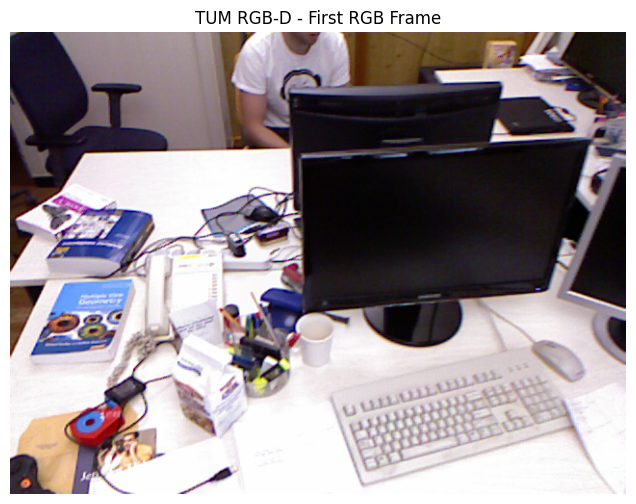

In [3]:
import cv2
import matplotlib.pyplot as plt

rgb_files = sorted((DATASET_PATH / "rgb").glob("*.png"))

img = cv2.imread(str(rgb_files[0]))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(img)
plt.title("TUM RGB-D - First RGB Frame")
plt.axis("off")
plt.show()

In [4]:
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from bisect import bisect_left

# Load RGB timestamp associations
rgb_data = pd.read_csv(
    DATASET_PATH / "rgb.txt",
    sep=r"\s+",
    comment="#",
    header=None,
    names=["timestamp", "filename"]
)

# Load ground-truth camera poses
gt_data = pd.read_csv(
    DATASET_PATH / "groundtruth.txt",
    sep=r"\s+",
    comment="#",
    header=None,
    names=["timestamp", "tx", "ty", "tz",
           "qx", "qy", "qz", "qw"]
)

print("RGB frames:", len(rgb_data))
print("Ground-truth poses:", len(gt_data))

print("\nRGB data:")
display(rgb_data.head())

print("\nGround truth:")
display(gt_data.head())

RGB frames: 798
Ground-truth poses: 3000

RGB data:


,timestamp,filename
0,1.305031e+09,rgb/1305031102.175304.png
1,1.305031e+09,rgb/1305031102.211214.png
2,1.305031e+09,rgb/1305031102.243211.png
3,1.305031e+09,rgb/1305031102.275326.png
4,1.305031e+09,rgb/1305031102.311267.png



Ground truth:


,timestamp,tx,ty,tz,qx,qy,qz,qw
0,1.305031e+09,1.3563,0.6305,1.6380,0.6132,0.5962,-0.3311,-0.3986
1,1.305031e+09,1.3543,0.6306,1.6360,0.6129,0.5966,-0.3316,-0.3980
2,1.305031e+09,1.3525,0.6306,1.6339,0.6136,0.5971,-0.3312,-0.3966
3,1.305031e+09,1.3502,0.6306,1.6318,0.6139,0.5972,-0.3312,-0.3959
4,1.305031e+09,1.3482,0.6308,1.6298,0.6148,0.5978,-0.3301,-0.3945


In [5]:
gt_timestamps = gt_data["timestamp"].values
rgb_timestamps = rgb_data["timestamp"].values

matches = []

for i, timestamp in enumerate(rgb_timestamps):
    idx = bisect_left(gt_timestamps, timestamp)

    candidates = []
    if idx < len(gt_timestamps):
        candidates.append(idx)
    if idx > 0:
        candidates.append(idx - 1)

    best_idx = min(
        candidates,
        key=lambda j: abs(gt_timestamps[j] - timestamp)
    )

    time_difference = abs(gt_timestamps[best_idx] - timestamp)

    if time_difference < 0.02:
        matches.append((i, best_idx))

print("Synchronized RGB-GT pairs:", len(matches))

Synchronized RGB-GT pairs: 796


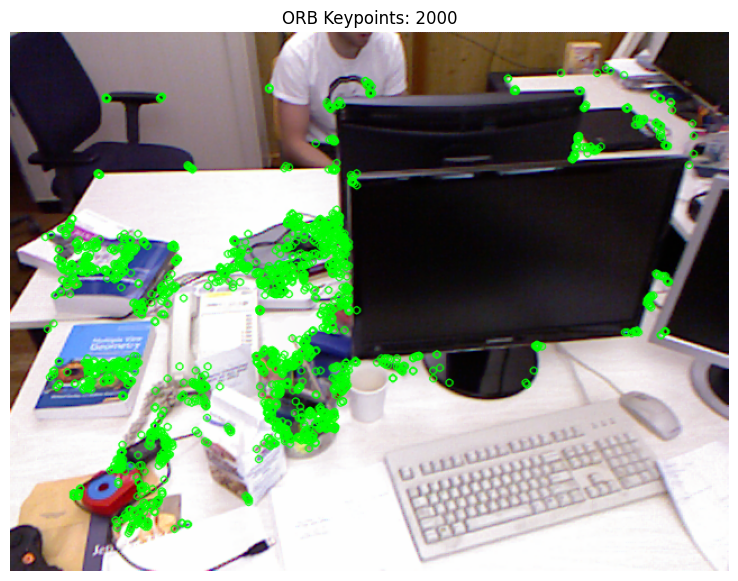

Camera matrix:
 [[517.3   0.  318.6]
 [  0.  516.5 255.3]
 [  0.    0.    1. ]]
Number of keypoints: 2000


In [6]:
# Camera intrinsics for TUM Freiburg 1 RGB camera
fx = 517.3
fy = 516.5
cx = 318.6
cy = 255.3

K = np.array([
    [fx, 0, cx],
    [0, fy, cy],
    [0,  0,  1]
], dtype=np.float64)

# Load first RGB frame
first_filename = rgb_data.iloc[0]["filename"]
first_image_path = DATASET_PATH / first_filename

image = cv2.imread(str(first_image_path))
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Create ORB detector
orb = cv2.ORB_create(nfeatures=2000)

keypoints, descriptors = orb.detectAndCompute(gray, None)

# Draw keypoints
orb_image = cv2.drawKeypoints(
    image,
    keypoints,
    None,
    color=(0, 255, 0),
    flags=cv2.DrawMatchesFlags_DEFAULT
)

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(orb_image, cv2.COLOR_BGR2RGB))
plt.title(f"ORB Keypoints: {len(keypoints)}")
plt.axis("off")
plt.show()

print("Camera matrix:\n", K)
print("Number of keypoints:", len(keypoints))

Keypoints in frame 1: 2000
Keypoints in frame 2: 2000
Good matches: 1283


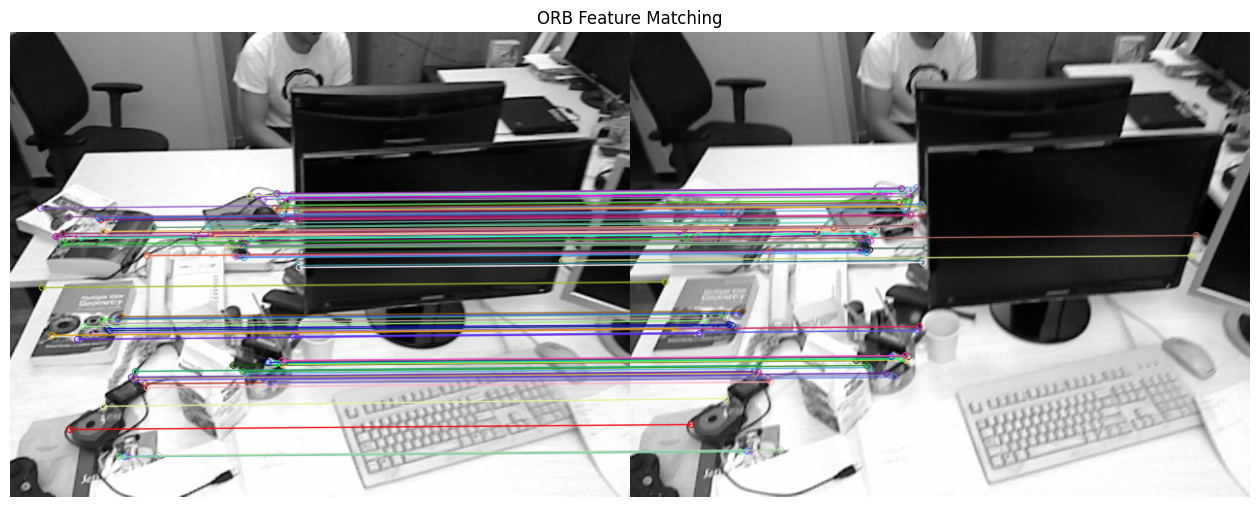

In [7]:
# Load two consecutive frames
img1 = cv2.imread(
    str(DATASET_PATH / rgb_data.iloc[0]["filename"]),
    cv2.IMREAD_GRAYSCALE
)

img2 = cv2.imread(
    str(DATASET_PATH / rgb_data.iloc[1]["filename"]),
    cv2.IMREAD_GRAYSCALE
)

# Detect ORB features
kp1, des1 = orb.detectAndCompute(img1, None)
kp2, des2 = orb.detectAndCompute(img2, None)

# Brute-force matcher using Hamming distance
bf = cv2.BFMatcher(cv2.NORM_HAMMING)

# K-nearest-neighbour matching
matches_knn = bf.knnMatch(des1, des2, k=2)

# Lowe's ratio test
good_matches = []

for pair in matches_knn:
    if len(pair) == 2:
        m, n = pair
        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

print("Keypoints in frame 1:", len(kp1))
print("Keypoints in frame 2:", len(kp2))
print("Good matches:", len(good_matches))

# Visualize matches
match_image = cv2.drawMatches(
    img1, kp1,
    img2, kp2,
    good_matches[:100],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16, 7))
plt.imshow(match_image, cmap="gray")
plt.title("ORB Feature Matching")
plt.axis("off")
plt.show()

In [8]:
# Extract matched keypoint coordinates
pts1 = np.float32([
    kp1[m.queryIdx].pt for m in good_matches
])

pts2 = np.float32([
    kp2[m.trainIdx].pt for m in good_matches
])

# Estimate Essential Matrix
E, mask = cv2.findEssentialMat(
    pts1,
    pts2,
    cameraMatrix=K,
    method=cv2.RANSAC,
    prob=0.999,
    threshold=1.0
)

print("Essential Matrix:")
print(E)

# Keep only RANSAC inlier matches
inlier_mask = mask.ravel().astype(bool)

inlier_pts1 = pts1[inlier_mask]
inlier_pts2 = pts2[inlier_mask]

print("\nTotal matches:", len(good_matches))
print("RANSAC inliers:", len(inlier_pts1))
print("Outliers:", len(good_matches) - len(inlier_pts1))
print("Inlier ratio:", round(len(inlier_pts1) / len(good_matches), 4))

Essential Matrix:
[[-1.75586221e-03 -6.54704054e-01  2.54681983e-01]
 [ 6.56025053e-01  5.69015500e-04  8.50412928e-02]
 [-2.49799785e-01 -8.05870359e-02 -1.08949175e-03]]

Total matches: 1283
RANSAC inliers: 1073
Outliers: 210
Inlier ratio: 0.8363


In [9]:
# Recover relative camera pose
num_inliers, R, t, pose_mask = cv2.recoverPose(
    E,
    pts1,
    pts2,
    cameraMatrix=K,
    mask=mask
)

print("Recovered pose inliers:", num_inliers)

print("\nRotation Matrix (R):")
print(R)

print("\nTranslation Vector (t):")
print(t)

print("\nTranslation direction:")
print(t / np.linalg.norm(t))

Recovered pose inliers: 89

Rotation Matrix (R):
[[ 9.99977095e-01 -4.90329276e-05  6.76812673e-03]
 [ 9.95141521e-05  9.99972180e-01 -7.45853486e-03]
 [-6.76757273e-03  7.45903755e-03  9.99949280e-01]]

Translation Vector (t):
[[ 0.11398777]
 [-0.35326699]
 [-0.92855222]]

Translation direction:
[[ 0.11398777]
 [-0.35326699]
 [-0.92855222]]


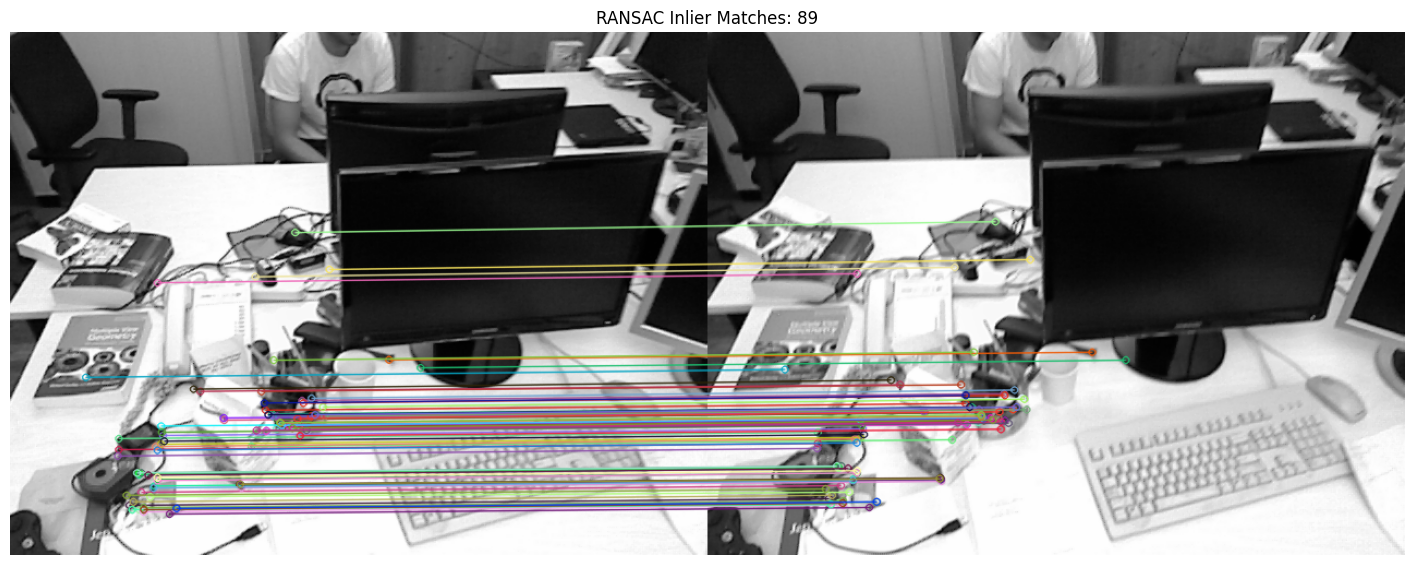

In [10]:
inlier_matches = [
    m for i, m in enumerate(good_matches)
    if pose_mask.ravel()[i]
]

inlier_image = cv2.drawMatches(
    img1, kp1,
    img2, kp2,
    inlier_matches[:150],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(18, 7))
plt.imshow(inlier_image, cmap="gray")
plt.title(f"RANSAC Inlier Matches: {num_inliers}")
plt.axis("off")
plt.show()

In [11]:
# Extract matched keypoint coordinates
pts1 = np.float32(
    [kp1[m.queryIdx].pt for m in good_matches]
)

pts2 = np.float32(
    [kp2[m.trainIdx].pt for m in good_matches]
)

# Estimate Essential Matrix using RANSAC
E, mask = cv2.findEssentialMat(
    pts1,
    pts2,
    K,
    method=cv2.RANSAC,
    prob=0.999,
    threshold=1.0
)

print("Essential Matrix shape:", E.shape)
print("RANSAC inliers:", int(mask.sum()))

# Use a copy because recoverPose modifies the supplied mask
retval, R, t, pose_mask = cv2.recoverPose(
    E,
    pts1,
    pts2,
    K,
    mask=mask.copy()
)

print("\nRecovered pose inliers:", retval)
print("Rotation:\n", R)
print("Translation:\n", t)
print("Pose inlier ratio:", retval / len(good_matches))

Essential Matrix shape: (3, 3)
RANSAC inliers: 1073

Recovered pose inliers: 89
Rotation:
 [[ 9.99977095e-01 -4.90329276e-05  6.76812673e-03]
 [ 9.95141521e-05  9.99972180e-01 -7.45853486e-03]
 [-6.76757273e-03  7.45903755e-03  9.99949280e-01]]
Translation:
 [[ 0.11398777]
 [-0.35326699]
 [-0.92855222]]
Pose inlier ratio: 0.06936866718628215


In [12]:
displacements = np.linalg.norm(pts2 - pts1, axis=1)

print("Mean feature displacement:",
      np.mean(displacements), "pixels")

print("Median feature displacement:",
      np.median(displacements), "pixels")

Mean feature displacement: 7.322171 pixels
Median feature displacement: 6.4398866 pixels


In [13]:
# Load depth timestamp associations
depth_data = pd.read_csv(
    DATASET_PATH / "depth.txt",
    sep=r"\s+",
    comment="#",
    header=None,
    names=["timestamp", "filename"]
)

print("Depth frames:", len(depth_data))
display(depth_data.head())

Depth frames: 798


,timestamp,filename
0,1.305031e+09,depth/1305031102.160407.png
1,1.305031e+09,depth/1305031102.194330.png
2,1.305031e+09,depth/1305031102.226738.png
3,1.305031e+09,depth/1305031102.262886.png
4,1.305031e+09,depth/1305031102.295279.png


RGB timestamp: 1305031102.175304
Depth timestamp: 1305031102.160407
Time difference: 0.014896869659423828
Depth image shape: (480, 640)
Depth data type: uint16
Minimum depth value: 0
Maximum depth value: 18587


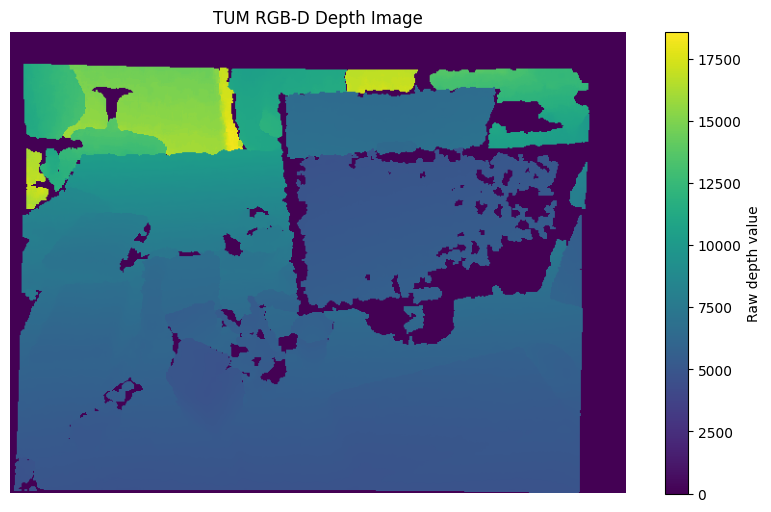

In [14]:
rgb_timestamp = rgb_data.iloc[0]["timestamp"]

depth_idx = np.argmin(
    np.abs(depth_data["timestamp"].values - rgb_timestamp)
)

depth_row = depth_data.iloc[depth_idx]

print("RGB timestamp:", rgb_timestamp)
print("Depth timestamp:", depth_row["timestamp"])
print("Time difference:",
      abs(rgb_timestamp - depth_row["timestamp"]))

depth_path = DATASET_PATH / depth_row["filename"]

depth_image = cv2.imread(
    str(depth_path),
    cv2.IMREAD_UNCHANGED
)

print("Depth image shape:", depth_image.shape)
print("Depth data type:", depth_image.dtype)
print("Minimum depth value:", depth_image.min())
print("Maximum depth value:", depth_image.max())

plt.figure(figsize=(10, 6))
plt.imshow(depth_image, cmap="viridis")
plt.colorbar(label="Raw depth value")
plt.title("TUM RGB-D Depth Image")
plt.axis("off")
plt.show()

In [15]:
DEPTH_SCALE = 5000.0

depth_metres = depth_image.astype(np.float32) / DEPTH_SCALE

valid_depth = depth_metres[
    (depth_metres > 0.1) & (depth_metres < 5.0)
]

print("Valid depth pixels:", len(valid_depth))
print("Average depth:", np.mean(valid_depth), "metres")

Valid depth pixels: 229875
Average depth: 1.4271832 metres


In [16]:
def get_nearest_depth(rgb_timestamp):
    idx = np.argmin(
        np.abs(depth_data["timestamp"].values - rgb_timestamp)
    )
    return depth_data.iloc[idx]

# First two RGB frames
rgb1_row = rgb_data.iloc[0]
rgb2_row = rgb_data.iloc[1]

img1 = cv2.imread(
    str(DATASET_PATH / rgb1_row["filename"]),
    cv2.IMREAD_GRAYSCALE
)

img2 = cv2.imread(
    str(DATASET_PATH / rgb2_row["filename"]),
    cv2.IMREAD_GRAYSCALE
)

# Find corresponding depth frames
depth1_row = get_nearest_depth(rgb1_row["timestamp"])
depth2_row = get_nearest_depth(rgb2_row["timestamp"])

depth1 = cv2.imread(
    str(DATASET_PATH / depth1_row["filename"]),
    cv2.IMREAD_UNCHANGED
)

depth2 = cv2.imread(
    str(DATASET_PATH / depth2_row["filename"]),
    cv2.IMREAD_UNCHANGED
)

print("RGB image shape:", img1.shape)
print("Depth image shape:", depth1.shape)

print("Frame 1 RGB-depth time difference:",
      abs(rgb1_row["timestamp"] - depth1_row["timestamp"]))

print("Frame 2 RGB-depth time difference:",
      abs(rgb2_row["timestamp"] - depth2_row["timestamp"]))

RGB image shape: (480, 640)
Depth image shape: (480, 640)
Frame 1 RGB-depth time difference: 0.014896869659423828
Frame 2 RGB-depth time difference: 0.015523910522460938


In [17]:
orb = cv2.ORB_create(nfeatures=3000)

kp1, des1 = orb.detectAndCompute(img1, None)
kp2, des2 = orb.detectAndCompute(img2, None)

bf = cv2.BFMatcher(cv2.NORM_HAMMING)

knn_matches = bf.knnMatch(des1, des2, k=2)

good_matches = []

for pair in knn_matches:
    if len(pair) == 2:
        m, n = pair
        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

print("Frame 1 keypoints:", len(kp1))
print("Frame 2 keypoints:", len(kp2))
print("Good matches:", len(good_matches))

Frame 1 keypoints: 2964
Frame 2 keypoints: 2970
Good matches: 1851


In [18]:
DEPTH_SCALE = 5000.0

object_points = []
image_points = []

for match in good_matches:

    # Matched pixel in frame 1
    u, v = kp1[match.queryIdx].pt

    u, v = int(round(u)), int(round(v))

    # Get depth from frame 1
    if not (0 <= v < depth1.shape[0] and
            0 <= u < depth1.shape[1]):
        continue

    z = float(depth1[v, u]) / DEPTH_SCALE

    # Reject invalid or excessively distant depth
    if z < 0.1 or z > 5.0:
        continue

    # Convert 2D pixel into 3D camera coordinates
    x = (u - cx) * z / fx
    y = (v - cy) * z / fy

    object_points.append([x, y, z])

    # Corresponding 2D pixel in frame 2
    u2, v2 = kp2[match.trainIdx].pt
    image_points.append([u2, v2])

object_points = np.array(object_points, dtype=np.float32)
image_points = np.array(image_points, dtype=np.float32)

print("Valid 3D-2D correspondences:", len(object_points))

Valid 3D-2D correspondences: 1554


In [19]:
success, rvec, tvec, inliers = cv2.solvePnPRansac(
    object_points,
    image_points,
    K,
    None,
    iterationsCount=200,
    reprojectionError=2.0,
    confidence=0.999,
    flags=cv2.SOLVEPNP_ITERATIVE
)

if success:
    R, _ = cv2.Rodrigues(rvec)

    print("PnP estimation successful!")
    print("\nRotation matrix:\n", R)
    print("\nTranslation vector:\n", tvec)

    print("\nPnP inliers:", len(inliers))
    print("PnP inlier ratio:",
          len(inliers) / len(object_points))

    print("\nEstimated translation magnitude:",
          np.linalg.norm(tvec), "metres")
else:
    print("PnP estimation failed. Check the correspondences.")

PnP estimation successful!

Rotation matrix:
 [[ 9.99971612e-01 -5.27273274e-04  7.51648573e-03]
 [ 5.53739683e-04  9.99993653e-01 -3.51946859e-03]
 [-7.51458230e-03  3.52353086e-03  9.99965557e-01]]

Translation vector:
 [[-0.00019316]
 [-0.00954393]
 [-0.01149439]]

PnP inliers: 1157
PnP inlier ratio: 0.7445302445302445

Estimated translation magnitude: 0.014941380054574474 metres


In [20]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Configuration
NUM_FRAMES = min(300, len(rgb_data))
DEPTH_SCALE = 5000.0

orb = cv2.ORB_create(nfeatures=2500)
bf = cv2.BFMatcher(cv2.NORM_HAMMING)

# Camera-to-world transformation
T_world_camera = np.eye(4)

# Store camera positions
trajectory = [T_world_camera[:3, 3].copy()]

# Store evaluation information
pose_inliers = []
translation_steps = []
failed_frames = []

# Cache depth timestamps
depth_timestamps = depth_data["timestamp"].values

def load_depth_for_timestamp(timestamp):
    idx = np.argmin(np.abs(depth_timestamps - timestamp))
    row = depth_data.iloc[idx]

    depth = cv2.imread(
        str(DATASET_PATH / row["filename"]),
        cv2.IMREAD_UNCHANGED
    )

    return depth

# Start VO
for i in range(1, NUM_FRAMES):

    # Load consecutive RGB frames
    timestamp1 = rgb_data.iloc[i-1]["timestamp"]
    timestamp2 = rgb_data.iloc[i]["timestamp"]

    img1 = cv2.imread(
        str(DATASET_PATH / rgb_data.iloc[i-1]["filename"]),
        cv2.IMREAD_GRAYSCALE
    )

    img2 = cv2.imread(
        str(DATASET_PATH / rgb_data.iloc[i]["filename"]),
        cv2.IMREAD_GRAYSCALE
    )

    depth1 = load_depth_for_timestamp(timestamp1)

    # Detect features
    kp1, des1 = orb.detectAndCompute(img1, None)
    kp2, des2 = orb.detectAndCompute(img2, None)

    if des1 is None or des2 is None:
        failed_frames.append(i)
        trajectory.append(T_world_camera[:3, 3].copy())
        continue

    # Match descriptors
    knn = bf.knnMatch(des1, des2, k=2)

    good = [
        m for pair in knn if len(pair) == 2
        for m, n in [pair]
        if m.distance < 0.75 * n.distance
    ]

    object_points = []
    image_points = []

    # Build 3D-2D correspondences
    for match in good:

        u, v = kp1[match.queryIdx].pt
        u, v = int(round(u)), int(round(v))

        if not (0 <= u < depth1.shape[1] and
                0 <= v < depth1.shape[0]):
            continue

        z = float(depth1[v, u]) / DEPTH_SCALE

        if not (0.1 < z < 5.0):
            continue

        x = (u - cx) * z / fx
        y = (v - cy) * z / fy

        object_points.append([x, y, z])

        u2, v2 = kp2[match.trainIdx].pt
        image_points.append([u2, v2])

    object_points = np.asarray(
        object_points, dtype=np.float32
    )

    image_points = np.asarray(
        image_points, dtype=np.float32
    )

    # Estimate relative camera pose
    success = False

    if len(object_points) >= 6:

        success, rvec, tvec, inliers = cv2.solvePnPRansac(
            object_points,
            image_points,
            K,
            None,
            iterationsCount=200,
            reprojectionError=2.0,
            confidence=0.999,
            flags=cv2.SOLVEPNP_ITERATIVE
        )

    if success and inliers is not None and len(inliers) >= 30:

        R, _ = cv2.Rodrigues(rvec)

        # Previous-camera to current-camera transformation
        T_current_previous = np.eye(4)
        T_current_previous[:3, :3] = R
        T_current_previous[:3, 3] = tvec.flatten()

        # Invert to get current-camera pose in previous coordinates
        T_previous_current = np.linalg.inv(T_current_previous)

        # Accumulate camera-to-world pose
        T_world_camera = (
            T_world_camera @ T_previous_current
        )

        pose_inliers.append(len(inliers))
        translation_steps.append(np.linalg.norm(tvec))

    else:
        failed_frames.append(i)

    trajectory.append(T_world_camera[:3, 3].copy())

    if i % 50 == 0:
        print(
            f"Processed {i}/{NUM_FRAMES} frames | "
            f"Successful poses: {len(pose_inliers)} | "
            f"Failed frames: {len(failed_frames)}"
        )

trajectory = np.array(trajectory)

print("\nVO processing completed!")
print("Trajectory shape:", trajectory.shape)
print("Successful poses:", len(pose_inliers))
print("Failed frames:", len(failed_frames))

Processed 50/300 frames | Successful poses: 50 | Failed frames: 0
Processed 100/300 frames | Successful poses: 100 | Failed frames: 0
Processed 150/300 frames | Successful poses: 150 | Failed frames: 0
Processed 200/300 frames | Successful poses: 200 | Failed frames: 0
Processed 250/300 frames | Successful poses: 250 | Failed frames: 0

VO processing completed!
Trajectory shape: (300, 3)
Successful poses: 299
Failed frames: 0


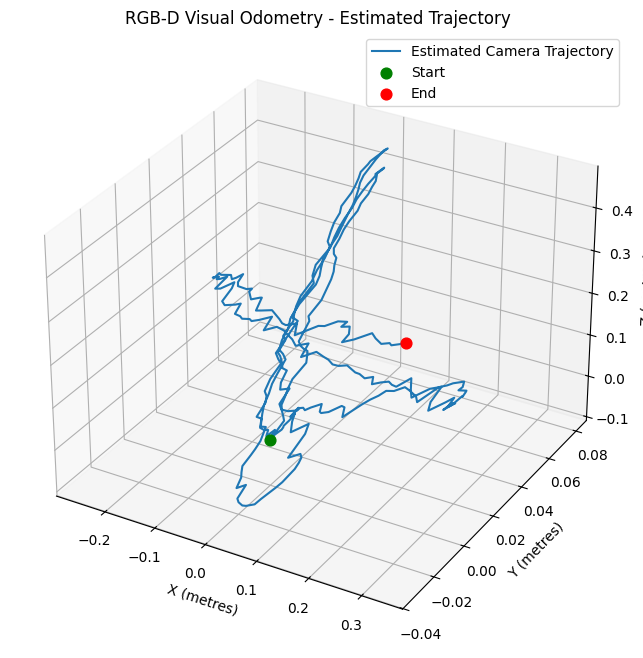

In [21]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

ax.plot(
    trajectory[:, 0],
    trajectory[:, 1],
    trajectory[:, 2],
    label="Estimated Camera Trajectory"
)

ax.scatter(
    trajectory[0, 0],
    trajectory[0, 1],
    trajectory[0, 2],
    color="green",
    label="Start",
    s=60
)

ax.scatter(
    trajectory[-1, 0],
    trajectory[-1, 1],
    trajectory[-1, 2],
    color="red",
    label="End",
    s=60
)

ax.set_xlabel("X (metres)")
ax.set_ylabel("Y (metres)")
ax.set_zlabel("Z (metres)")
ax.set_title("RGB-D Visual Odometry - Estimated Trajectory")
ax.legend()

plt.show()

In [22]:
print("Average PnP inliers:",
      np.mean(pose_inliers))

print("Average translation per successful frame:",
      np.mean(translation_steps), "metres")

print("Total estimated path length:",
      np.sum(np.linalg.norm(
          np.diff(trajectory, axis=0), axis=1
      )), "metres")

Average PnP inliers: 1052.3177257525083
Average translation per successful frame: 0.011724824146159293 metres
Total estimated path length: 3.50572241970163 metres


In [23]:
# Get timestamps for the first 300 RGB frames
vo_timestamps = rgb_data.iloc[:len(trajectory)]["timestamp"].values
gt_timestamps = gt_data["timestamp"].values

gt_positions = []
matched_indices = []
time_errors = []

for timestamp in vo_timestamps:

    idx = np.argmin(np.abs(gt_timestamps - timestamp))
    time_error = abs(gt_timestamps[idx] - timestamp)

    if time_error > 0.02:
        continue

    row = gt_data.iloc[idx]

    gt_positions.append([
        row["tx"], row["ty"], row["tz"]
    ])

    matched_indices.append(len(gt_positions) - 1)
    time_errors.append(time_error)

gt_positions = np.array(gt_positions)

# Select corresponding estimated positions
estimated_positions = trajectory[:len(gt_positions)]

print("Estimated positions:", len(estimated_positions))
print("Ground-truth positions:", len(gt_positions))
print("Maximum timestamp difference:",
      max(time_errors), "seconds")

Estimated positions: 298
Ground-truth positions: 298
Maximum timestamp difference: 0.007564067840576172 seconds


In [24]:
def align_trajectories(source, target):

    # source: estimated trajectory
    # target: ground-truth trajectory

    source_mean = np.mean(source, axis=0)
    target_mean = np.mean(target, axis=0)

    source_centered = source - source_mean
    target_centered = target - target_mean

    H = source_centered.T @ target_centered

    U, S, Vt = np.linalg.svd(H)

    D = np.eye(3)

    if np.linalg.det(U @ Vt) < 0:
        D[2, 2] = -1

    R_align = U @ D @ Vt

    aligned = (
        source_centered @ R_align
        + target_mean
    )

    return aligned, R_align


aligned_trajectory, R_align = align_trajectories(
    estimated_positions,
    gt_positions
)

print("Trajectory alignment completed!")
print("Alignment rotation:\n", R_align)

Trajectory alignment completed!
Alignment rotation:
 [[ 0.09457047  0.99374294  0.05942554]
 [ 0.66097337 -0.01804086 -0.75019246]
 [-0.74442637  0.11022475 -0.65854376]]


In [25]:
position_errors = np.linalg.norm(
    aligned_trajectory - gt_positions,
    axis=1
)

ate_rmse = np.sqrt(np.mean(position_errors**2))
ate_mean = np.mean(position_errors)
ate_median = np.median(position_errors)
ate_max = np.max(position_errors)

print("========== ATE RESULTS ==========")
print("ATE RMSE:", ate_rmse, "metres")
print("ATE Mean:", ate_mean, "metres")
print("ATE Median:", ate_median, "metres")
print("ATE Maximum:", ate_max, "metres")

========== ATE RESULTS ==========
ATE RMSE: 0.033795044681313904 metres
ATE Mean: 0.03011667775832392 metres
ATE Median: 0.028856067398077404 metres
ATE Maximum: 0.07188303546618936 metres


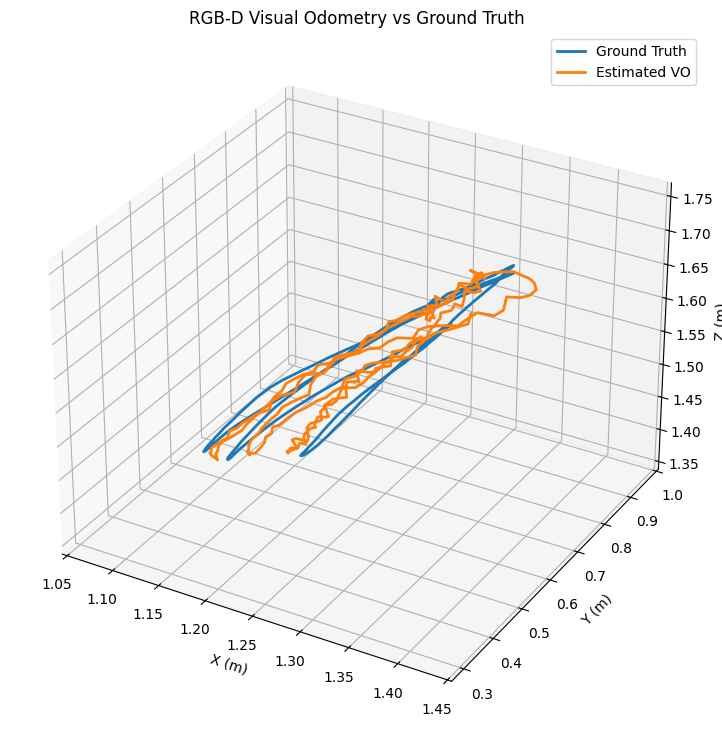

In [26]:
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

ax.plot(
    gt_positions[:, 0],
    gt_positions[:, 1],
    gt_positions[:, 2],
    label="Ground Truth",
    linewidth=2
)

ax.plot(
    aligned_trajectory[:, 0],
    aligned_trajectory[:, 1],
    aligned_trajectory[:, 2],
    label="Estimated VO",
    linewidth=2
)

ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.set_zlabel("Z (m)")

ax.set_title("RGB-D Visual Odometry vs Ground Truth")
ax.legend()

plt.show()

In [27]:
estimated_motion = np.diff(
    aligned_trajectory, axis=0
)

ground_truth_motion = np.diff(
    gt_positions, axis=0
)

rpe_errors = np.linalg.norm(
    estimated_motion - ground_truth_motion,
    axis=1
)

rpe_rmse = np.sqrt(np.mean(rpe_errors**2))
rpe_mean = np.mean(rpe_errors)

print("========== RPE RESULTS ==========")
print("RPE RMSE:", rpe_rmse, "metres/frame")
print("RPE Mean:", rpe_mean, "metres/frame")

========== RPE RESULTS ==========
RPE RMSE: 0.006159967387531681 metres/frame
RPE Mean: 0.005296465340051333 metres/frame


In [28]:
# Check timestamp synchronization
print("Number of VO timestamps:", len(vo_timestamps))
print("Number of GT matches:", len(gt_positions))

print("Mean timestamp difference:",
      np.mean(time_errors), "seconds")

print("Maximum timestamp difference:",
      np.max(time_errors), "seconds")

# Check trajectory movement
print("\nEstimated trajectory range:")
print(np.ptp(trajectory, axis=0))

print("\nGround truth trajectory range:")
print(np.ptp(gt_positions, axis=0))

# Check alignment residual
print("\nATE RMSE:", ate_rmse)
print("RPE RMSE:", rpe_rmse)

Number of VO timestamps: 300
Number of GT matches: 298
Mean timestamp difference: 0.002662620288413643 seconds
Maximum timestamp difference: 0.007564067840576172 seconds

Estimated trajectory range:
[0.58929108 0.11185418 0.52837829]

Ground truth trajectory range:
[0.3288 0.6533 0.3977]

ATE RMSE: 0.033795044681313904
RPE RMSE: 0.006159967387531681


In [29]:
vo_gt_pairs = []

for i, timestamp in enumerate(vo_timestamps):

    idx = np.argmin(
        np.abs(gt_timestamps - timestamp)
    )

    error = abs(gt_timestamps[idx] - timestamp)

    if error <= 0.02:
        vo_gt_pairs.append((i, idx))

vo_indices = [p[0] for p in vo_gt_pairs]
gt_indices = [p[1] for p in vo_gt_pairs]

estimated_positions = trajectory[vo_indices]

gt_positions_correct = gt_data.iloc[
    gt_indices
][["tx", "ty", "tz"]].values

print("Matched pairs:", len(vo_indices))
print("Estimated shape:", estimated_positions.shape)
print("Ground truth shape:", gt_positions_correct.shape)

Matched pairs: 298
Estimated shape: (298, 3)
Ground truth shape: (298, 3)


In [30]:
aligned_trajectory, R_align = align_trajectories(
    estimated_positions,
    gt_positions_correct
)

errors = np.linalg.norm(
    aligned_trajectory - gt_positions_correct,
    axis=1
)

print("Corrected ATE RMSE:",
      np.sqrt(np.mean(errors**2)), "metres")

print("Corrected ATE Mean:",
      np.mean(errors), "metres")

print("Corrected ATE Median:",
      np.median(errors), "metres")

Corrected ATE RMSE: 0.03427707939416466 metres
Corrected ATE Mean: 0.030177581728239696 metres
Corrected ATE Median: 0.025330712830020426 metres


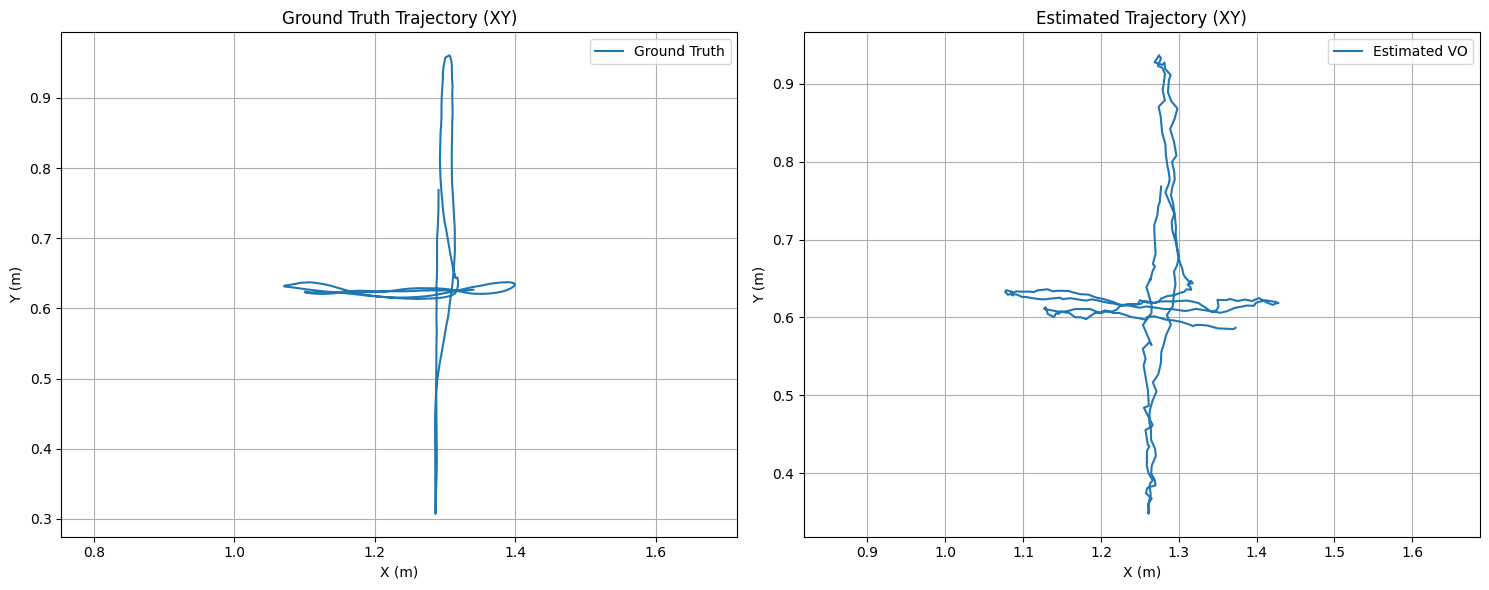

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Ground truth XY
axes[0].plot(
    gt_positions_correct[:, 0],
    gt_positions_correct[:, 1],
    label="Ground Truth"
)

axes[0].set_title("Ground Truth Trajectory (XY)")
axes[0].set_xlabel("X (m)")
axes[0].set_ylabel("Y (m)")
axes[0].axis("equal")
axes[0].legend()
axes[0].grid()

# Estimated XY after alignment
axes[1].plot(
    aligned_trajectory[:, 0],
    aligned_trajectory[:, 1],
    label="Estimated VO"
)

axes[1].set_title("Estimated Trajectory (XY)")
axes[1].set_xlabel("X (m)")
axes[1].set_ylabel("Y (m)")
axes[1].axis("equal")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

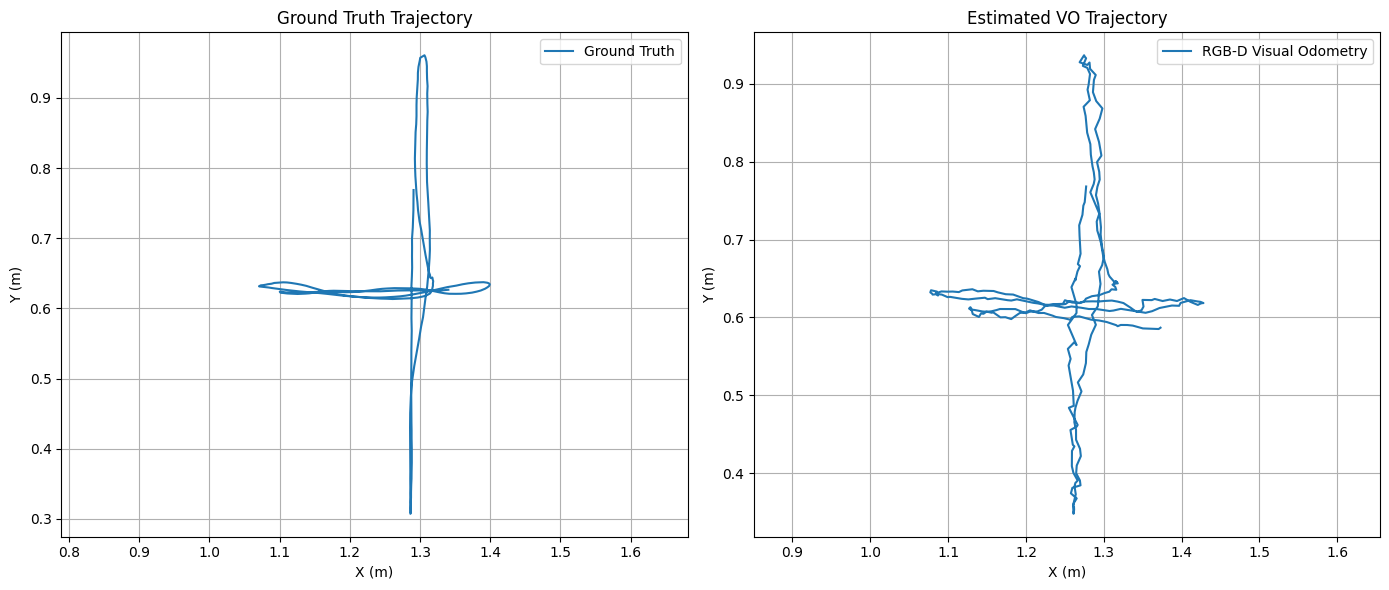

In [32]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Ground truth
axes[0].plot(
    gt_positions_correct[:, 0],
    gt_positions_correct[:, 1],
    label="Ground Truth"
)

axes[0].set_title("Ground Truth Trajectory")
axes[0].set_xlabel("X (m)")
axes[0].set_ylabel("Y (m)")
axes[0].axis("equal")
axes[0].grid()
axes[0].legend()

# Estimated trajectory after rigid alignment
axes[1].plot(
    aligned_trajectory[:, 0],
    aligned_trajectory[:, 1],
    label="RGB-D Visual Odometry"
)

axes[1].set_title("Estimated VO Trajectory")
axes[1].set_xlabel("X (m)")
axes[1].set_ylabel("Y (m)")
axes[1].axis("equal")
axes[1].grid()
axes[1].legend()

plt.tight_layout()
plt.show()

In [33]:
estimated_motion = np.diff(aligned_trajectory, axis=0)
ground_truth_motion = np.diff(gt_positions_correct, axis=0)

rpe_errors = np.linalg.norm(
    estimated_motion - ground_truth_motion,
    axis=1
)

print("Translation RPE RMSE:",
      np.sqrt(np.mean(rpe_errors**2)), "m/frame")

print("Translation RPE Mean:",
      np.mean(rpe_errors), "m/frame")

print("Translation RPE Median:",
      np.median(rpe_errors), "m/frame")

Translation RPE RMSE: 0.006361569817215373 m/frame
Translation RPE Mean: 0.005324240625994522 m/frame
Translation RPE Median: 0.004503682649588212 m/frame


In [34]:
TOTAL_FRAMES = len(rgb_data)

print("Total RGB frames:", TOTAL_FRAMES)
print("Currently processed:", len(trajectory))
print("Remaining frames:", TOTAL_FRAMES - len(trajectory))

Total RGB frames: 798
Currently processed: 300
Remaining frames: 498


In [36]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

# Camera intrinsics
fx, fy = 517.3, 516.5
cx, cy = 318.6, 255.3

K = np.array([
    [fx, 0, cx],
    [0, fy, cy],
    [0,  0,  1]
], dtype=np.float64)

DEPTH_SCALE = 5000.0

TOTAL_FRAMES = len(rgb_data)

# ORB feature detector
orb = cv2.ORB_create(nfeatures=2500)

# Feature matcher
matcher = cv2.BFMatcher(cv2.NORM_HAMMING)

# Initial world-to-camera trajectory convention:
# T_world_camera maps camera coordinates into world coordinates.
T_world_camera = np.eye(4)

pose_history = [T_world_camera.copy()]
trajectory_full = [T_world_camera[:3, 3].copy()]

inlier_history = []
translation_history = []
failed_frames = []

print("Frames to process:", TOTAL_FRAMES)

Frames to process: 798


In [37]:
for i in tqdm(range(1, TOTAL_FRAMES)):

    # Load consecutive RGB frames
    rgb1_path = DATASET_PATH / rgb_data.iloc[i-1]["filename"]
    rgb2_path = DATASET_PATH / rgb_data.iloc[i]["filename"]

    img1 = cv2.imread(str(rgb1_path), cv2.IMREAD_GRAYSCALE)
    img2 = cv2.imread(str(rgb2_path), cv2.IMREAD_GRAYSCALE)

    if img1 is None or img2 is None:
        failed_frames.append(i)
        pose_history.append(T_world_camera.copy())
        trajectory_full.append(T_world_camera[:3, 3].copy())
        continue

    # Find nearest depth frame for the first RGB timestamp
    timestamp = rgb_data.iloc[i-1]["timestamp"]

    depth_idx = np.argmin(
        np.abs(depth_data["timestamp"].values - timestamp)
    )

    depth_path = DATASET_PATH / depth_data.iloc[depth_idx]["filename"]

    depth = cv2.imread(str(depth_path), cv2.IMREAD_UNCHANGED)

    if depth is None:
        failed_frames.append(i)
        pose_history.append(T_world_camera.copy())
        trajectory_full.append(T_world_camera[:3, 3].copy())
        continue

    # Extract ORB features
    kp1, des1 = orb.detectAndCompute(img1, None)
    kp2, des2 = orb.detectAndCompute(img2, None)

    if des1 is None or des2 is None:
        failed_frames.append(i)
        pose_history.append(T_world_camera.copy())
        trajectory_full.append(T_world_camera[:3, 3].copy())
        continue

    # Match features
    matches = matcher.knnMatch(des1, des2, k=2)

    good_matches = [
        m for m, n in matches
        if m.distance < 0.75 * n.distance
    ]

    # Build 3D-2D correspondences
    object_points = []
    image_points = []

    for m in good_matches:

        u, v = kp1[m.queryIdx].pt
        u2, v2 = kp2[m.trainIdx].pt

        u, v = int(round(u)), int(round(v))

        if not (0 <= u < depth.shape[1] and
                0 <= v < depth.shape[0]):
            continue

        z = float(depth[v, u]) / DEPTH_SCALE

        if z <= 0.1 or z >= 5.0:
            continue

        x = (u - cx) * z / fx
        y = (v - cy) * z / fy

        object_points.append([x, y, z])
        image_points.append([u2, v2])

    if len(object_points) < 30:
        failed_frames.append(i)
        pose_history.append(T_world_camera.copy())
        trajectory_full.append(T_world_camera[:3, 3].copy())
        continue

    object_points = np.asarray(
        object_points, dtype=np.float32
    )

    image_points = np.asarray(
        image_points, dtype=np.float32
    )

    # Estimate motion from previous camera to current camera
    success, rvec, tvec, inliers = cv2.solvePnPRansac(
        object_points,
        image_points,
        K,
        None,
        iterationsCount=200,
        reprojectionError=2.0,
        confidence=0.999,
        flags=cv2.SOLVEPNP_ITERATIVE
    )

    if success and inliers is not None and len(inliers) >= 30:

        R, _ = cv2.Rodrigues(rvec)

        # PnP gives transformation from previous camera to current camera
        T_current_previous = np.eye(4)

        T_current_previous[:3, :3] = R
        T_current_previous[:3, 3] = tvec.flatten()

        # Invert to obtain current camera pose relative to previous camera
        T_previous_current = np.linalg.inv(T_current_previous)

        # Accumulate camera pose in world coordinates
        T_world_camera = (
            T_world_camera @ T_previous_current
        )

        inlier_history.append(len(inliers))
        translation_history.append(
            np.linalg.norm(tvec)
        )

    else:
        failed_frames.append(i)

    # Store pose for every frame, including failed frames
    pose_history.append(T_world_camera.copy())
    trajectory_full.append(T_world_camera[:3, 3].copy())

  0%|          | 0/797 [00:00<?, ?it/s]

In [38]:
trajectory_full = np.array(trajectory_full)
pose_history = np.array(pose_history)

print("\nVO processing completed!")

print("Trajectory shape:", trajectory_full.shape)
print("Pose history shape:", pose_history.shape)

print("Successful poses:", TOTAL_FRAMES - 1 - len(failed_frames))
print("Failed frames:", len(failed_frames))

print("Average PnP inliers:",
      np.mean(inlier_history))

print("Average translation per successful frame:",
      np.mean(translation_history), "metres")

print("Total estimated path length:",
      np.sum(np.linalg.norm(
          np.diff(trajectory_full, axis=0),
          axis=1
      )), "metres")


VO processing completed!
Trajectory shape: (798, 3)
Pose history shape: (798, 4, 4)
Successful poses: 797
Failed frames: 0
Average PnP inliers: 1076.6850690087829
Average translation per successful frame: 0.010431021283159016 metres
Total estimated path length: 8.313523962677737 metres


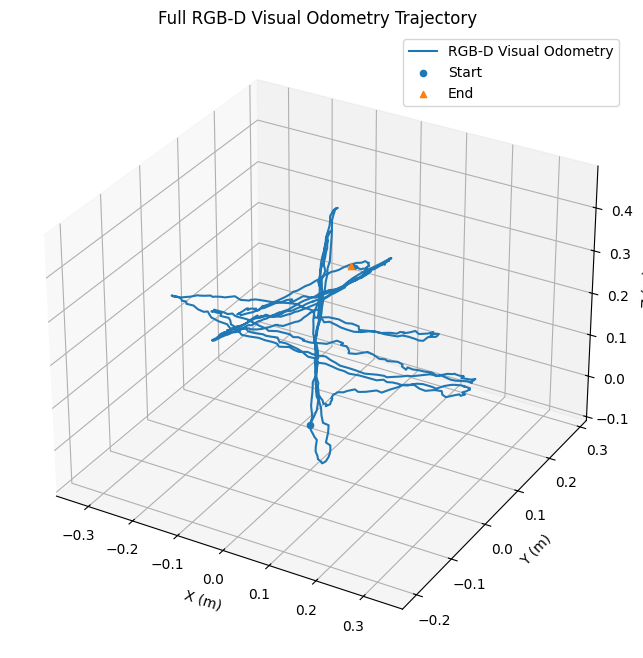

In [39]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

ax.plot(
    trajectory_full[:, 0],
    trajectory_full[:, 1],
    trajectory_full[:, 2],
    label="RGB-D Visual Odometry"
)

ax.scatter(
    trajectory_full[0, 0],
    trajectory_full[0, 1],
    trajectory_full[0, 2],
    marker="o",
    label="Start"
)

ax.scatter(
    trajectory_full[-1, 0],
    trajectory_full[-1, 1],
    trajectory_full[-1, 2],
    marker="^",
    label="End"
)

ax.set_title("Full RGB-D Visual Odometry Trajectory")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.set_zlabel("Z (m)")
ax.legend()

plt.show()

In [40]:
from scipy.spatial.transform import Rotation

# Build VO timestamps and positions
vo_timestamps_full = rgb_data.iloc[:len(trajectory_full)][
    "timestamp"
].to_numpy()

gt_timestamps = gt_data["timestamp"].to_numpy()

# Match timestamps using nearest-neighbour matching
pairs = []

for i, timestamp in enumerate(vo_timestamps_full):
    idx = np.argmin(np.abs(gt_timestamps - timestamp))
    error = abs(gt_timestamps[idx] - timestamp)

    if error <= 0.02:
        pairs.append((i, idx, error))

# Keep unique GT matches
used_gt = set()
unique_pairs = []

for vo_idx, gt_idx, error in pairs:
    if gt_idx not in used_gt:
        unique_pairs.append((vo_idx, gt_idx, error))
        used_gt.add(gt_idx)

vo_indices = np.array([p[0] for p in unique_pairs])
gt_indices = np.array([p[1] for p in unique_pairs])

estimated_positions = trajectory_full[vo_indices]

gt_matched = gt_data.iloc[gt_indices]

gt_positions = gt_matched[
    ["tx", "ty", "tz"]
].to_numpy()

print("Total VO frames:", len(trajectory_full))
print("Matched frames:", len(vo_indices))
print("Mean timestamp error:",
      np.mean([p[2] for p in unique_pairs]))
print("Maximum timestamp error:",
      np.max([p[2] for p in unique_pairs]))

Total VO frames: 798
Matched frames: 796
Mean timestamp error: 0.0029826496713724567
Maximum timestamp error: 0.007564067840576172


In [41]:
aligned_trajectory, R_align = align_trajectories(
    estimated_positions,
    gt_positions
)

position_errors = np.linalg.norm(
    aligned_trajectory - gt_positions,
    axis=1
)

ate_rmse = np.sqrt(np.mean(position_errors**2))
ate_mean = np.mean(position_errors)
ate_median = np.median(position_errors)
ate_max = np.max(position_errors)

print("FULL SEQUENCE ATE")
print("------------------")
print("ATE RMSE:", ate_rmse, "metres")
print("ATE Mean:", ate_mean, "metres")
print("ATE Median:", ate_median, "metres")
print("ATE Maximum:", ate_max, "metres")

FULL SEQUENCE ATE
------------------
ATE RMSE: 0.033698881701666905 metres
ATE Mean: 0.02964183283719732 metres
ATE Median: 0.027451311482506922 metres
ATE Maximum: 0.08593375401859647 metres


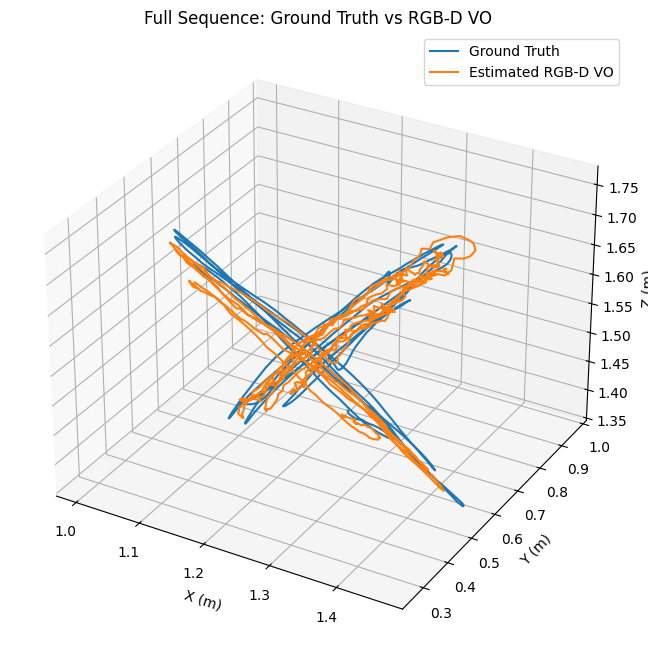

In [42]:
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

ax.plot(
    gt_positions[:, 0],
    gt_positions[:, 1],
    gt_positions[:, 2],
    label="Ground Truth"
)

ax.plot(
    aligned_trajectory[:, 0],
    aligned_trajectory[:, 1],
    aligned_trajectory[:, 2],
    label="Estimated RGB-D VO"
)

ax.set_title("Full Sequence: Ground Truth vs RGB-D VO")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.set_zlabel("Z (m)")
ax.legend()

plt.show()

In [43]:
print("Pose history shape:", pose_history.shape)

print("Expected shape:",
      (TOTAL_FRAMES, 4, 4))

print("Matched pose count:", len(vo_indices))

print("First estimated pose:\n", pose_history[0])

print("Last estimated pose:\n", pose_history[-1])

Pose history shape: (798, 4, 4)
Expected shape: (798, 4, 4)
Matched pose count: 796
First estimated pose:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Last estimated pose:
 [[ 0.98297216 -0.00688233 -0.18362563 -0.01078908]
 [ 0.03814647  0.98517141  0.16727866  0.13111108]
 [ 0.17975145 -0.17143493  0.9686586   0.27923605]
 [ 0.          0.          0.          1.        ]]


In [44]:
from scipy.spatial.transform import Rotation
import numpy as np

gt_pose_history = []

for _, row in gt_matched.iterrows():

    T = np.eye(4)

    # TUM quaternion order: qx, qy, qz, qw
    quat = [
        row["qx"],
        row["qy"],
        row["qz"],
        row["qw"]
    ]

    T[:3, :3] = Rotation.from_quat(quat).as_matrix()

    T[:3, 3] = [
        row["tx"],
        row["ty"],
        row["tz"]
    ]

    gt_pose_history.append(T)

gt_pose_history = np.array(gt_pose_history)

# Estimated poses corresponding to matched VO frames
estimated_pose_history = pose_history[vo_indices]

print("Estimated poses:", estimated_pose_history.shape)
print("Ground truth poses:", gt_pose_history.shape)

Estimated poses: (796, 4, 4)
Ground truth poses: (796, 4, 4)


In [45]:
def calculate_6dof_rpe(
    estimated_poses,
    ground_truth_poses,
    vo_indices,
    delta
):

    index_map = {
        int(vo_idx): i
        for i, vo_idx in enumerate(vo_indices)
    }

    translation_errors = []
    rotation_errors = []

    for vo_idx in vo_indices:

        next_idx = int(vo_idx) + delta

        if next_idx not in index_map:
            continue

        i = index_map[int(vo_idx)]
        j = index_map[next_idx]

        # Relative estimated transformation
        T_est_rel = (
            np.linalg.inv(estimated_poses[i])
            @ estimated_poses[j]
        )

        # Relative ground-truth transformation
        T_gt_rel = (
            np.linalg.inv(ground_truth_poses[i])
            @ ground_truth_poses[j]
        )

        # Relative pose error
        T_error = (
            np.linalg.inv(T_gt_rel)
            @ T_est_rel
        )

        # Translation error
        translation_error = np.linalg.norm(
            T_error[:3, 3]
        )

        # Rotation error in degrees
        rotation_error = Rotation.from_matrix(
            T_error[:3, :3]
        ).magnitude()

        rotation_error = np.degrees(rotation_error)

        translation_errors.append(translation_error)
        rotation_errors.append(rotation_error)

    translation_errors = np.array(translation_errors)
    rotation_errors = np.array(rotation_errors)

    return {
        "pairs": len(translation_errors),
        "translation_rmse": np.sqrt(
            np.mean(translation_errors**2)
        ),
        "translation_mean": np.mean(translation_errors),
        "rotation_rmse_deg": np.sqrt(
            np.mean(rotation_errors**2)
        ),
        "rotation_mean_deg": np.mean(rotation_errors)
    }

In [46]:
for delta in [1, 10, 30]:

    results = calculate_6dof_rpe(
        estimated_pose_history,
        gt_pose_history,
        vo_indices,
        delta
    )

    print(f"\nRPE at {delta} frame(s)")
    print("-" * 35)

    for key, value in results.items():
        print(f"{key}: {value}")


RPE at 1 frame(s)
-----------------------------------
pairs: 794
translation_rmse: 0.0060378660384082655
translation_mean: 0.005030313099764966
rotation_rmse_deg: 0.4051895782854719
rotation_mean_deg: 0.3441869481621522

RPE at 10 frame(s)
-----------------------------------
pairs: 784
translation_rmse: 0.017305542647664596
translation_mean: 0.015056369690433715
rotation_rmse_deg: 1.0444133908257418
rotation_mean_deg: 0.9091868443392912

RPE at 30 frame(s)
-----------------------------------
pairs: 764
translation_rmse: 0.033816761427393274
translation_mean: 0.029660395475373535
rotation_rmse_deg: 2.003680222133322
rotation_mean_deg: 1.7457172432816686


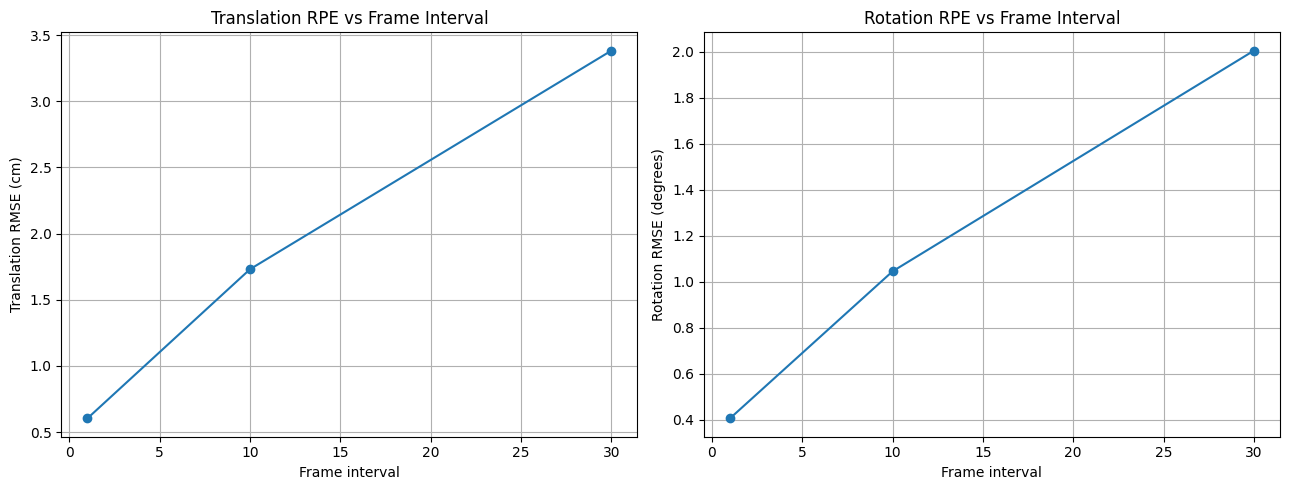

In [47]:
intervals = [1, 10, 30]

translation_rmse_values = []
rotation_rmse_values = []

for delta in intervals:

    result = calculate_6dof_rpe(
        estimated_pose_history,
        gt_pose_history,
        vo_indices,
        delta
    )

    translation_rmse_values.append(
        result["translation_rmse"] * 100
    )  # metres to centimetres

    rotation_rmse_values.append(
        result["rotation_rmse_deg"]
    )

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    intervals,
    translation_rmse_values,
    marker="o"
)
axes[0].set_title("Translation RPE vs Frame Interval")
axes[0].set_xlabel("Frame interval")
axes[0].set_ylabel("Translation RMSE (cm)")
axes[0].grid()

axes[1].plot(
    intervals,
    rotation_rmse_values,
    marker="o"
)
axes[1].set_title("Rotation RPE vs Frame Interval")
axes[1].set_xlabel("Frame interval")
axes[1].set_ylabel("Rotation RMSE (degrees)")
axes[1].grid()

plt.tight_layout()
plt.show()

In [48]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

orb_v2 = cv2.ORB_create(
    nfeatures=3000,
    scaleFactor=1.2,
    nlevels=8,
    edgeThreshold=31,
    fastThreshold=15
)

matcher_v2 = cv2.BFMatcher(cv2.NORM_HAMMING)

T_world_camera_v2 = np.eye(4)

pose_history_v2 = [T_world_camera_v2.copy()]
trajectory_v2 = [T_world_camera_v2[:3, 3].copy()]

inliers_v2 = []
reprojection_errors_v2 = []
match_counts_v2 = []
failed_frames_v2 = []

print("VO v2 initialized")
print("Total frames:", len(rgb_data))

VO v2 initialized
Total frames: 798


In [49]:
for i in tqdm(range(1, len(rgb_data))):

    # Load consecutive RGB frames
    img1_path = DATASET_PATH / rgb_data.iloc[i-1]["filename"]
    img2_path = DATASET_PATH / rgb_data.iloc[i]["filename"]

    img1 = cv2.imread(str(img1_path), cv2.IMREAD_GRAYSCALE)
    img2 = cv2.imread(str(img2_path), cv2.IMREAD_GRAYSCALE)

    if img1 is None or img2 is None:
        failed_frames_v2.append(i)
        pose_history_v2.append(T_world_camera_v2.copy())
        trajectory_v2.append(T_world_camera_v2[:3, 3].copy())
        continue

    # Find nearest depth frame to previous RGB frame
    timestamp = rgb_data.iloc[i-1]["timestamp"]

    depth_idx = np.argmin(
        np.abs(depth_data["timestamp"].values - timestamp)
    )

    depth_path = DATASET_PATH / depth_data.iloc[depth_idx]["filename"]

    depth = cv2.imread(str(depth_path), cv2.IMREAD_UNCHANGED)

    if depth is None:
        failed_frames_v2.append(i)
        pose_history_v2.append(T_world_camera_v2.copy())
        trajectory_v2.append(T_world_camera_v2[:3, 3].copy())
        continue

    # Extract ORB features
    kp1, des1 = orb_v2.detectAndCompute(img1, None)
    kp2, des2 = orb_v2.detectAndCompute(img2, None)

    if des1 is None or des2 is None:
        failed_frames_v2.append(i)
        pose_history_v2.append(T_world_camera_v2.copy())
        trajectory_v2.append(T_world_camera_v2[:3, 3].copy())
        continue

    # Match in both directions
    forward = matcher_v2.knnMatch(des1, des2, k=2)
    backward = matcher_v2.knnMatch(des2, des1, k=2)

    forward_good = [
        m for pair in forward if len(pair) == 2
        for m, n in [pair]
        if m.distance < 0.75 * n.distance
    ]

    backward_good = [
        m for pair in backward if len(pair) == 2
        for m, n in [pair]
        if m.distance < 0.75 * n.distance
    ]

    # Reverse matches must agree with forward matches
    backward_pairs = {
        (m.trainIdx, m.queryIdx)
        for m in backward_good
    }

    mutual_matches = [
        m for m in forward_good
        if (m.queryIdx, m.trainIdx) in backward_pairs
    ]

    match_counts_v2.append(len(mutual_matches))

    # Build RGB-D 3D-to-2D correspondences
    object_points = []
    image_points = []

    for m in mutual_matches:

        u, v = kp1[m.queryIdx].pt
        u2, v2 = kp2[m.trainIdx].pt

        u = int(round(u))
        v = int(round(v))

        if not (0 <= u < depth.shape[1] and
                0 <= v < depth.shape[0]):
            continue

        z = float(depth[v, u]) / DEPTH_SCALE

        if not (0.1 < z < 5.0):
            continue

        x = (u - cx) * z / fx
        y = (v - cy) * z / fy

        object_points.append([x, y, z])
        image_points.append([u2, v2])

    if len(object_points) < 30:
        failed_frames_v2.append(i)
        pose_history_v2.append(T_world_camera_v2.copy())
        trajectory_v2.append(T_world_camera_v2[:3, 3].copy())
        continue

    object_points = np.asarray(
        object_points, dtype=np.float32
    )

    image_points = np.asarray(
        image_points, dtype=np.float32
    )

    # Initial robust PnP
    success, rvec, tvec, inliers = cv2.solvePnPRansac(
        object_points,
        image_points,
        K,
        None,
        iterationsCount=300,
        reprojectionError=2.0,
        confidence=0.999,
        flags=cv2.SOLVEPNP_ITERATIVE
    )

    if not success or inliers is None or len(inliers) < 30:
        failed_frames_v2.append(i)
        pose_history_v2.append(T_world_camera_v2.copy())
        trajectory_v2.append(T_world_camera_v2[:3, 3].copy())
        continue

    # Refine using RANSAC inliers
    inlier_idx = inliers.flatten()

    success_refine, rvec, tvec = cv2.solvePnP(
        object_points[inlier_idx],
        image_points[inlier_idx],
        K,
        None,
        rvec,
        tvec,
        True,
        flags=cv2.SOLVEPNP_ITERATIVE
    )

    if not success_refine:
        failed_frames_v2.append(i)
        pose_history_v2.append(T_world_camera_v2.copy())
        trajectory_v2.append(T_world_camera_v2[:3, 3].copy())
        continue

    # Calculate reprojection errors
    projected, _ = cv2.projectPoints(
        object_points,
        rvec,
        tvec,
        K,
        None
    )

    errors = np.linalg.norm(
        projected.reshape(-1, 2) - image_points,
        axis=1
    )

    # Retain geometrically consistent correspondences
    refined_idx = np.where(errors < 3.0)[0]

    if len(refined_idx) < 30:
        failed_frames_v2.append(i)
        pose_history_v2.append(T_world_camera_v2.copy())
        trajectory_v2.append(T_world_camera_v2[:3, 3].copy())
        continue

    # Final pose refinement
    success_final, rvec, tvec = cv2.solvePnP(
        object_points[refined_idx],
        image_points[refined_idx],
        K,
        None,
        rvec,
        tvec,
        True,
        flags=cv2.SOLVEPNP_ITERATIVE
    )

    if not success_final:
        failed_frames_v2.append(i)
        pose_history_v2.append(T_world_camera_v2.copy())
        trajectory_v2.append(T_world_camera_v2[:3, 3].copy())
        continue

    # Final reprojection error
    projected, _ = cv2.projectPoints(
        object_points[refined_idx],
        rvec,
        tvec,
        K,
        None
    )

    final_errors = np.linalg.norm(
        projected.reshape(-1, 2) - image_points[refined_idx],
        axis=1
    )

    R, _ = cv2.Rodrigues(rvec)

    T_current_previous = np.eye(4)
    T_current_previous[:3, :3] = R
    T_current_previous[:3, 3] = tvec.flatten()

    # Invert relative transformation and accumulate
    T_previous_current = np.linalg.inv(T_current_previous)

    T_world_camera_v2 = (
        T_world_camera_v2 @ T_previous_current
    )

    inliers_v2.append(len(refined_idx))
    reprojection_errors_v2.append(np.mean(final_errors))

    pose_history_v2.append(T_world_camera_v2.copy())
    trajectory_v2.append(T_world_camera_v2[:3, 3].copy())


trajectory_v2 = np.asarray(trajectory_v2)
pose_history_v2 = np.asarray(pose_history_v2)

print("VO v2 completed")

  0%|          | 0/797 [00:00<?, ?it/s]

VO v2 completed


In [50]:
print("Trajectory shape:", trajectory_v2.shape)
print("Pose history shape:", pose_history_v2.shape)

print("Successful poses:",
      len(rgb_data) - 1 - len(failed_frames_v2))

print("Failed frames:", len(failed_frames_v2))

print("Average mutual matches:",
      np.mean(match_counts_v2))

print("Average refined inliers:",
      np.mean(inliers_v2))

print("Average reprojection error:",
      np.mean(reprojection_errors_v2), "pixels")

print("Total path length:",
      np.sum(np.linalg.norm(
          np.diff(trajectory_v2, axis=0),
          axis=1
      )), "metres")

Trajectory shape: (798, 3)
Pose history shape: (798, 4, 4)
Successful poses: 797
Failed frames: 0
Average mutual matches: 1500.1894604767879
Average refined inliers: 1309.879548306148
Average reprojection error: 1.0681664 pixels
Total path length: 8.115020655212906 metres


In [51]:
vo_timestamps_v2 = rgb_data.iloc[:len(trajectory_v2)][
    "timestamp"
].to_numpy()

pairs_v2 = []

for i, timestamp in enumerate(vo_timestamps_v2):

    idx = np.argmin(
        np.abs(gt_timestamps - timestamp)
    )

    error = abs(gt_timestamps[idx] - timestamp)

    if error <= 0.02:
        pairs_v2.append((i, idx, error))

# Unique GT timestamps
used_gt = set()
unique_pairs_v2 = []

for vo_idx, gt_idx, error in pairs_v2:
    if gt_idx not in used_gt:
        unique_pairs_v2.append((vo_idx, gt_idx, error))
        used_gt.add(gt_idx)

vo_indices_v2 = np.array([p[0] for p in unique_pairs_v2])
gt_indices_v2 = np.array([p[1] for p in unique_pairs_v2])

estimated_v2 = trajectory_v2[vo_indices_v2]

gt_v2 = gt_data.iloc[gt_indices_v2][
    ["tx", "ty", "tz"]
].to_numpy()

aligned_v2, R_align_v2 = align_trajectories(
    estimated_v2,
    gt_v2
)

errors_v2 = np.linalg.norm(
    aligned_v2 - gt_v2,
    axis=1
)

ate_v2 = np.sqrt(np.mean(errors_v2**2))

print("VO v2 ATE RMSE:", ate_v2, "metres")
print("VO v2 ATE Mean:", np.mean(errors_v2), "metres")
print("VO v2 ATE Median:", np.median(errors_v2), "metres")
print("VO v2 ATE Maximum:", np.max(errors_v2), "metres")

VO v2 ATE RMSE: 0.04443726243039442 metres
VO v2 ATE Mean: 0.04112902257899732 metres
VO v2 ATE Median: 0.04118055030358794 metres
VO v2 ATE Maximum: 0.08866478376242919 metres


In [52]:
baseline_ate = 0.033698881701666905

print("BASELINE ATE:", baseline_ate, "m")
print("VO V2 ATE:", ate_v2, "m")

improvement = (
    (baseline_ate - ate_v2) / baseline_ate
) * 100

print("ATE improvement:", improvement, "%")

BASELINE ATE: 0.033698881701666905 m
VO V2 ATE: 0.04443726243039442 m
ATE improvement: -31.865688671195112 %


In [53]:
# Prepare v1 and v2 matched pose arrays
baseline_poses = pose_history[vo_indices]

v2_poses = pose_history_v2[vo_indices_v2]

# Ground truth for each implementation
gt_poses_v1 = []

for gt_idx in gt_indices:
    gt_poses_v1.append(gt_pose_history[0] if False else np.eye(4))

# Reconstruct GT poses using original matched GT indices
gt_poses_v1 = []

for gt_idx in gt_indices:
    row = gt_data.iloc[gt_idx]

    T = np.eye(4)

    T[:3, :3] = Rotation.from_quat([
        row["qx"], row["qy"], row["qz"], row["qw"]
    ]).as_matrix()

    T[:3, 3] = [row["tx"], row["ty"], row["tz"]]

    gt_poses_v1.append(T)

gt_poses_v1 = np.array(gt_poses_v1)

# Reconstruct GT poses for v2
gt_poses_v2 = []

for gt_idx in gt_indices_v2:
    row = gt_data.iloc[gt_idx]

    T = np.eye(4)

    T[:3, :3] = Rotation.from_quat([
        row["qx"], row["qy"], row["qz"], row["qw"]
    ]).as_matrix()

    T[:3, 3] = [row["tx"], row["ty"], row["tz"]]

    gt_poses_v2.append(T)

gt_poses_v2 = np.array(gt_poses_v2)

In [54]:
for version, poses, gt_poses, indices in [
    ("Baseline v1", baseline_poses, gt_poses_v1, vo_indices),
    ("Improved v2", v2_poses, gt_poses_v2, vo_indices_v2)
]:

    print("\n", version)

    for delta in [1, 10, 30]:

        result = calculate_6dof_rpe(
            poses,
            gt_poses,
            indices,
            delta
        )

        print(
            f"{delta} frames | "
            f"Translation RMSE: "
            f"{result['translation_rmse']:.5f} m | "
            f"Rotation RMSE: "
            f"{result['rotation_rmse_deg']:.4f} deg"
        )


 Baseline v1
1 frames | Translation RMSE: 0.00604 m | Rotation RMSE: 0.4052 deg
10 frames | Translation RMSE: 0.01731 m | Rotation RMSE: 1.0444 deg
30 frames | Translation RMSE: 0.03382 m | Rotation RMSE: 2.0037 deg

 Improved v2
1 frames | Translation RMSE: 0.00556 m | Rotation RMSE: 0.3843 deg
10 frames | Translation RMSE: 0.01634 m | Rotation RMSE: 1.0097 deg
30 frames | Translation RMSE: 0.03280 m | Rotation RMSE: 2.0064 deg


In [55]:
# Find common VO frame indices
common_indices = np.intersect1d(
    vo_indices,
    vo_indices_v2
)

# Map VO frame indices to corresponding GT indices
gt_map_v1 = dict(zip(vo_indices, gt_indices))
gt_map_v2 = dict(zip(vo_indices_v2, gt_indices_v2))

# Verify that both versions use the same GT timestamps
common_gt_indices = np.array([
    gt_map_v1[i] for i in common_indices
])

assert np.array_equal(
    common_gt_indices,
    np.array([gt_map_v2[i] for i in common_indices])
)

# Extract matching trajectories
v1_common = trajectory_full[common_indices]
v2_common = trajectory_v2[common_indices]

gt_common = gt_data.iloc[common_gt_indices][
    ["tx", "ty", "tz"]
].to_numpy()

print("Common frames:", len(common_indices))

Common frames: 796


In [56]:
# Independently align each trajectory to the same ground truth
v1_aligned, _ = align_trajectories(
    v1_common,
    gt_common
)

v2_aligned, _ = align_trajectories(
    v2_common,
    gt_common
)

# Calculate frame-wise errors
v1_errors = np.linalg.norm(
    v1_aligned - gt_common,
    axis=1
)

v2_errors = np.linalg.norm(
    v2_aligned - gt_common,
    axis=1
)

print("V1 ATE RMSE:",
      np.sqrt(np.mean(v1_errors**2)))

print("V2 ATE RMSE:",
      np.sqrt(np.mean(v2_errors**2)))

print("V1 maximum error:", np.max(v1_errors))
print("V2 maximum error:", np.max(v2_errors))

V1 ATE RMSE: 0.033698881701666905
V2 ATE RMSE: 0.04443726243039442
V1 maximum error: 0.08593375401859647
V2 maximum error: 0.08866478376242919


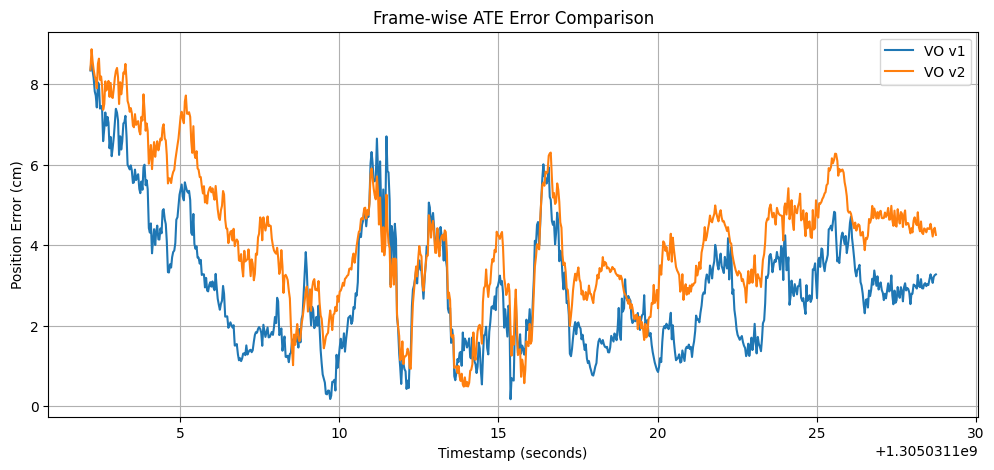

In [57]:
timestamps_common = rgb_data.iloc[
    common_indices
]["timestamp"].to_numpy()

plt.figure(figsize=(12, 5))

plt.plot(
    timestamps_common,
    v1_errors * 100,
    label="VO v1"
)

plt.plot(
    timestamps_common,
    v2_errors * 100,
    label="VO v2"
)

plt.xlabel("Timestamp (seconds)")
plt.ylabel("Position Error (cm)")
plt.title("Frame-wise ATE Error Comparison")
plt.grid()
plt.legend()

plt.show()

In [58]:
i = 100

img1 = cv2.imread(
    str(DATASET_PATH / rgb_data.iloc[i]["filename"]),
    cv2.IMREAD_GRAYSCALE
)

img2 = cv2.imread(
    str(DATASET_PATH / rgb_data.iloc[i+1]["filename"]),
    cv2.IMREAD_GRAYSCALE
)

kp1, des1 = orb_v2.detectAndCompute(img1, None)
kp2, des2 = orb_v2.detectAndCompute(img2, None)

forward = matcher_v2.knnMatch(des1, des2, k=2)
backward = matcher_v2.knnMatch(des2, des1, k=2)

forward_good = [
    m for pair in forward if len(pair) == 2
    for m, n in [pair]
    if m.distance < 0.75 * n.distance
]

backward_good = [
    m for pair in backward if len(pair) == 2
    for m, n in [pair]
    if m.distance < 0.75 * n.distance
]

backward_pairs = {
    (m.trainIdx, m.queryIdx)
    for m in backward_good
}

mutual_matches = [
    m for m in forward_good
    if (m.queryIdx, m.trainIdx) in backward_pairs
]

print("Forward matches:", len(forward_good))
print("Backward matches:", len(backward_good))
print("Mutual matches:", len(mutual_matches))

Forward matches: 2025
Backward matches: 2025
Mutual matches: 1788


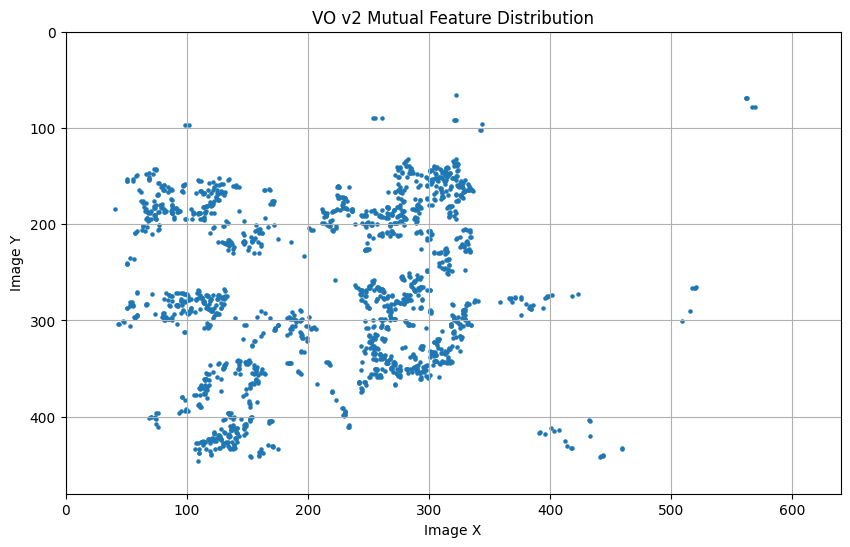

In [59]:
points = np.array([
    kp1[m.queryIdx].pt
    for m in mutual_matches
])

plt.figure(figsize=(10, 6))

plt.scatter(
    points[:, 0],
    points[:, 1],
    s=5
)

plt.xlim(0, 640)
plt.ylim(480, 0)

plt.title("VO v2 Mutual Feature Distribution")
plt.xlabel("Image X")
plt.ylabel("Image Y")
plt.grid()

plt.show()

In [60]:
n = len(v1_errors)

sections = {
    "Beginning": (0, n // 4),
    "Early-middle": (n // 4, n // 2),
    "Late-middle": (n // 2, 3 * n // 4),
    "End": (3 * n // 4, n)
}

for name, (start, end) in sections.items():

    print("\n", name)

    print(
        "V1 RMSE:",
        np.sqrt(np.mean(v1_errors[start:end]**2))
    )

    print(
        "V2 RMSE:",
        np.sqrt(np.mean(v2_errors[start:end]**2))
    )


 Beginning
V1 RMSE: 0.04405743240761502
V2 RMSE: 0.059248567054023565

 Early-middle
V1 RMSE: 0.03052111487978903
V2 RMSE: 0.03247563078271537

 Late-middle
V1 RMSE: 0.026333917416314172
V2 RMSE: 0.034993676357715386

 End
V1 RMSE: 0.03124719989736138
V2 RMSE: 0.045924552164523805


In [61]:
orb_v3 = cv2.ORB_create(nfeatures=2500)
matcher_v3 = cv2.BFMatcher(cv2.NORM_HAMMING)

T_world_camera_v3 = np.eye(4)

pose_history_v3 = [T_world_camera_v3.copy()]
trajectory_v3 = [T_world_camera_v3[:3, 3].copy()]

inliers_v3 = []
selected_matches_v3 = []
failed_frames_v3 = []

In [62]:
def select_spatial_matches(
    matches,
    keypoints,
    image_width=640,
    image_height=480,
    grid_cols=8,
    grid_rows=6,
    max_per_cell=25
):

    cells = {}

    for m in matches:

        x, y = keypoints[m.queryIdx].pt

        col = min(int(x / (image_width / grid_cols)), grid_cols - 1)
        row = min(int(y / (image_height / grid_rows)), grid_rows - 1)

        cell_id = (row, col)

        if cell_id not in cells:
            cells[cell_id] = []

        cells[cell_id].append(m)

    selected = []

    for cell_matches in cells.values():

        cell_matches.sort(key=lambda m: m.distance)

        selected.extend(cell_matches[:max_per_cell])

    return selected

In [63]:
for i in tqdm(range(1, len(rgb_data))):

    img1 = cv2.imread(
        str(DATASET_PATH / rgb_data.iloc[i-1]["filename"]),
        cv2.IMREAD_GRAYSCALE
    )

    img2 = cv2.imread(
        str(DATASET_PATH / rgb_data.iloc[i]["filename"]),
        cv2.IMREAD_GRAYSCALE
    )

    if img1 is None or img2 is None:
        failed_frames_v3.append(i)
        pose_history_v3.append(T_world_camera_v3.copy())
        trajectory_v3.append(T_world_camera_v3[:3, 3].copy())
        continue

    timestamp = rgb_data.iloc[i-1]["timestamp"]

    depth_idx = np.argmin(
        np.abs(depth_data["timestamp"].values - timestamp)
    )

    depth = cv2.imread(
        str(DATASET_PATH / depth_data.iloc[depth_idx]["filename"]),
        cv2.IMREAD_UNCHANGED
    )

    if depth is None:
        failed_frames_v3.append(i)
        pose_history_v3.append(T_world_camera_v3.copy())
        trajectory_v3.append(T_world_camera_v3[:3, 3].copy())
        continue

    kp1, des1 = orb_v3.detectAndCompute(img1, None)
    kp2, des2 = orb_v3.detectAndCompute(img2, None)

    if des1 is None or des2 is None:
        failed_frames_v3.append(i)
        pose_history_v3.append(T_world_camera_v3.copy())
        trajectory_v3.append(T_world_camera_v3[:3, 3].copy())
        continue

    matches = matcher_v3.knnMatch(des1, des2, k=2)

    good_matches = [
        m for pair in matches if len(pair) == 2
        for m, n in [pair]
        if m.distance < 0.75 * n.distance
    ]

    # New v3 step: spatially distribute matches
    selected = select_spatial_matches(
        good_matches,
        kp1
    )

    selected_matches_v3.append(len(selected))

    object_points = []
    image_points = []

    for m in selected:

        u, v = kp1[m.queryIdx].pt
        u2, v2 = kp2[m.trainIdx].pt

        u, v = int(round(u)), int(round(v))

        if not (0 <= u < depth.shape[1] and
                0 <= v < depth.shape[0]):
            continue

        z = float(depth[v, u]) / DEPTH_SCALE

        if not (0.1 < z < 5.0):
            continue

        x = (u - cx) * z / fx
        y = (v - cy) * z / fy

        object_points.append([x, y, z])
        image_points.append([u2, v2])

    if len(object_points) < 30:
        failed_frames_v3.append(i)
        pose_history_v3.append(T_world_camera_v3.copy())
        trajectory_v3.append(T_world_camera_v3[:3, 3].copy())
        continue

    object_points = np.asarray(
        object_points, dtype=np.float32
    )

    image_points = np.asarray(
        image_points, dtype=np.float32
    )

    success, rvec, tvec, inliers = cv2.solvePnPRansac(
        object_points,
        image_points,
        K,
        None,
        iterationsCount=200,
        reprojectionError=2.0,
        confidence=0.999,
        flags=cv2.SOLVEPNP_ITERATIVE
    )

    if success and inliers is not None and len(inliers) >= 30:

        R, _ = cv2.Rodrigues(rvec)

        T_current_previous = np.eye(4)
        T_current_previous[:3, :3] = R
        T_current_previous[:3, 3] = tvec.flatten()

        T_world_camera_v3 = (
            T_world_camera_v3 @ np.linalg.inv(T_current_previous)
        )

        inliers_v3.append(len(inliers))

    else:
        failed_frames_v3.append(i)

    pose_history_v3.append(T_world_camera_v3.copy())
    trajectory_v3.append(T_world_camera_v3[:3, 3].copy())


trajectory_v3 = np.asarray(trajectory_v3)
pose_history_v3 = np.asarray(pose_history_v3)

print("VO v3 completed")
print("Trajectory:", trajectory_v3.shape)
print("Successful poses:", len(rgb_data) - 1 - len(failed_frames_v3))
print("Failed frames:", len(failed_frames_v3))
print("Average selected matches:", np.mean(selected_matches_v3))
print("Average PnP inliers:", np.mean(inliers_v3))

  0%|          | 0/797 [00:00<?, ?it/s]

VO v3 completed
Trajectory: (798, 3)
Successful poses: 797
Failed frames: 0
Average selected matches: 510.3111668757842
Average PnP inliers: 388.8180677540778


In [64]:
vo_timestamps_v3 = rgb_data.iloc[:len(trajectory_v3)][
    "timestamp"
].to_numpy()

pairs_v3 = []

for i, timestamp in enumerate(vo_timestamps_v3):

    idx = np.argmin(np.abs(gt_timestamps - timestamp))
    error = abs(gt_timestamps[idx] - timestamp)

    if error <= 0.02:
        pairs_v3.append((i, idx, error))

used_gt = set()
unique_pairs_v3 = []

for vo_idx, gt_idx, error in pairs_v3:
    if gt_idx not in used_gt:
        unique_pairs_v3.append((vo_idx, gt_idx, error))
        used_gt.add(gt_idx)

vo_indices_v3 = np.array([p[0] for p in unique_pairs_v3])
gt_indices_v3 = np.array([p[1] for p in unique_pairs_v3])

estimated_v3 = trajectory_v3[vo_indices_v3]

gt_v3 = gt_data.iloc[gt_indices_v3][
    ["tx", "ty", "tz"]
].to_numpy()

aligned_v3, _ = align_trajectories(
    estimated_v3,
    gt_v3
)

errors_v3 = np.linalg.norm(
    aligned_v3 - gt_v3,
    axis=1
)

ate_v3 = np.sqrt(np.mean(errors_v3**2))

print("VO v3 ATE RMSE:", ate_v3, "metres")
print("VO v3 ATE Mean:", np.mean(errors_v3))
print("VO v3 ATE Median:", np.median(errors_v3))
print("VO v3 ATE Maximum:", np.max(errors_v3))

VO v3 ATE RMSE: 0.06160324575325164 metres
VO v3 ATE Mean: 0.056095350463847865
VO v3 ATE Median: 0.054314172673663834
VO v3 ATE Maximum: 0.1335476984642567


In [65]:
import numpy as np
import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path("/content/drive/MyDrive/VO_Project_Results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save estimated camera trajectory and full poses
np.save(OUTPUT_DIR / "v1_trajectory.npy", trajectory_full)
np.save(OUTPUT_DIR / "v1_pose_history.npy", pose_history)

# Save trajectory as CSV
trajectory_df = pd.DataFrame(
    trajectory_full,
    columns=["x", "y", "z"]
)

trajectory_df.insert(
    0, "timestamp",
    rgb_data["timestamp"].iloc[:len(trajectory_full)].to_numpy()
)

trajectory_df.to_csv(
    OUTPUT_DIR / "v1_trajectory.csv",
    index=False
)

print("V1 results saved successfully!")
print("Output directory:", OUTPUT_DIR)
print("Trajectory shape:", trajectory_full.shape)
print("Pose history shape:", pose_history.shape)

V1 results saved successfully!
Output directory: /content/drive/MyDrive/VO_Project_Results
Trajectory shape: (798, 3)
Pose history shape: (798, 4, 4)


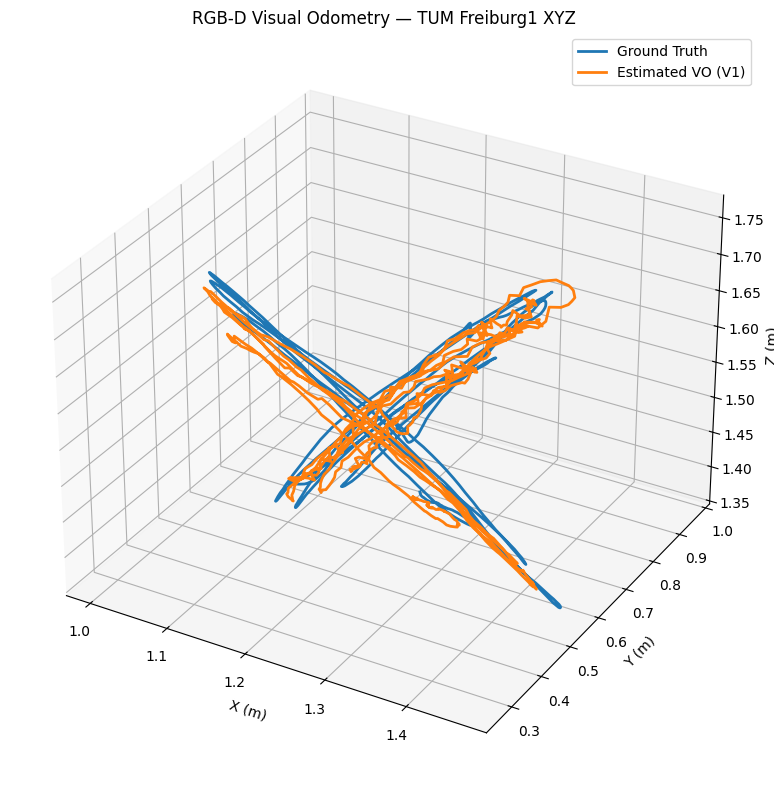

In [67]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

# Plot ground truth positions using the matched numpy array gt_positions
ax.plot(
    gt_positions[:, 0],
    gt_positions[:, 1],
    gt_positions[:, 2],
    label="Ground Truth",
    linewidth=2
)

# Plot the aligned estimated trajectory
ax.plot(
    aligned_trajectory[:, 0],
    aligned_trajectory[:, 1],
    aligned_trajectory[:, 2],
    label="Estimated VO (V1)",
    linewidth=2
)

ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.set_zlabel("Z (m)")

ax.set_title("RGB-D Visual Odometry — TUM Freiburg1 XYZ")
ax.legend()
plt.tight_layout()
plt.show()

In [68]:
!wget -O /content/VisDrone_0001.mp4 \
"https://huggingface.co/datasets/choucsan/SIS-Bench/resolve/main/video/VisDrone/VisDrone_0001.mp4?download=true"

--2026-11-08 05:45:05--  https://huggingface.co/datasets/choucsan/SIS-Bench/resolve/main/video/VisDrone/VisDrone_0001.mp4?download=true
Resolving huggingface.co (huggingface.co)... 99.86.18.96, 99.86.18.52, 99.86.18.89, ...
Connecting to huggingface.co (huggingface.co)|99.86.18.96|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/6a537dd57b97d2898437829f/b7bd52d3b8574ff028f24784466393060f8d2844af366f8b826c37e062213f8a?user_id=public&response-content-disposition=attachment%3B+filename*%3DUTF-8%27%27VisDrone_0001.mp4%3B+filename%3D%22VisDrone_0001.mp4%22%3B&response-content-type=video%2Fmp4&X-Xet-Cas-Uid=public&xip=-Pt4AZ5pLUs&Expires=1794120305&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNmE1MzdkZDU3Yjk3ZDI4OTg0Mzc4MjlmL2I3YmQ1MmQzYjg1NzRmZjAyOGYyNDc4NDQ2NjM5MzA2MGY4ZDI4NDRhZjM2NmY4YjgyNmMzN2UwNjIyMTNmOGFcXD91c2VyX2lkPXB1YmxpYyZyZXNwb25zZS1jb250ZW50LWRpc3Bvc2l0aW9uPSomc

FPS: 15.0
Total frames: 196
Resolution: 1904 x 1070
Duration: 13.066666666666666 seconds


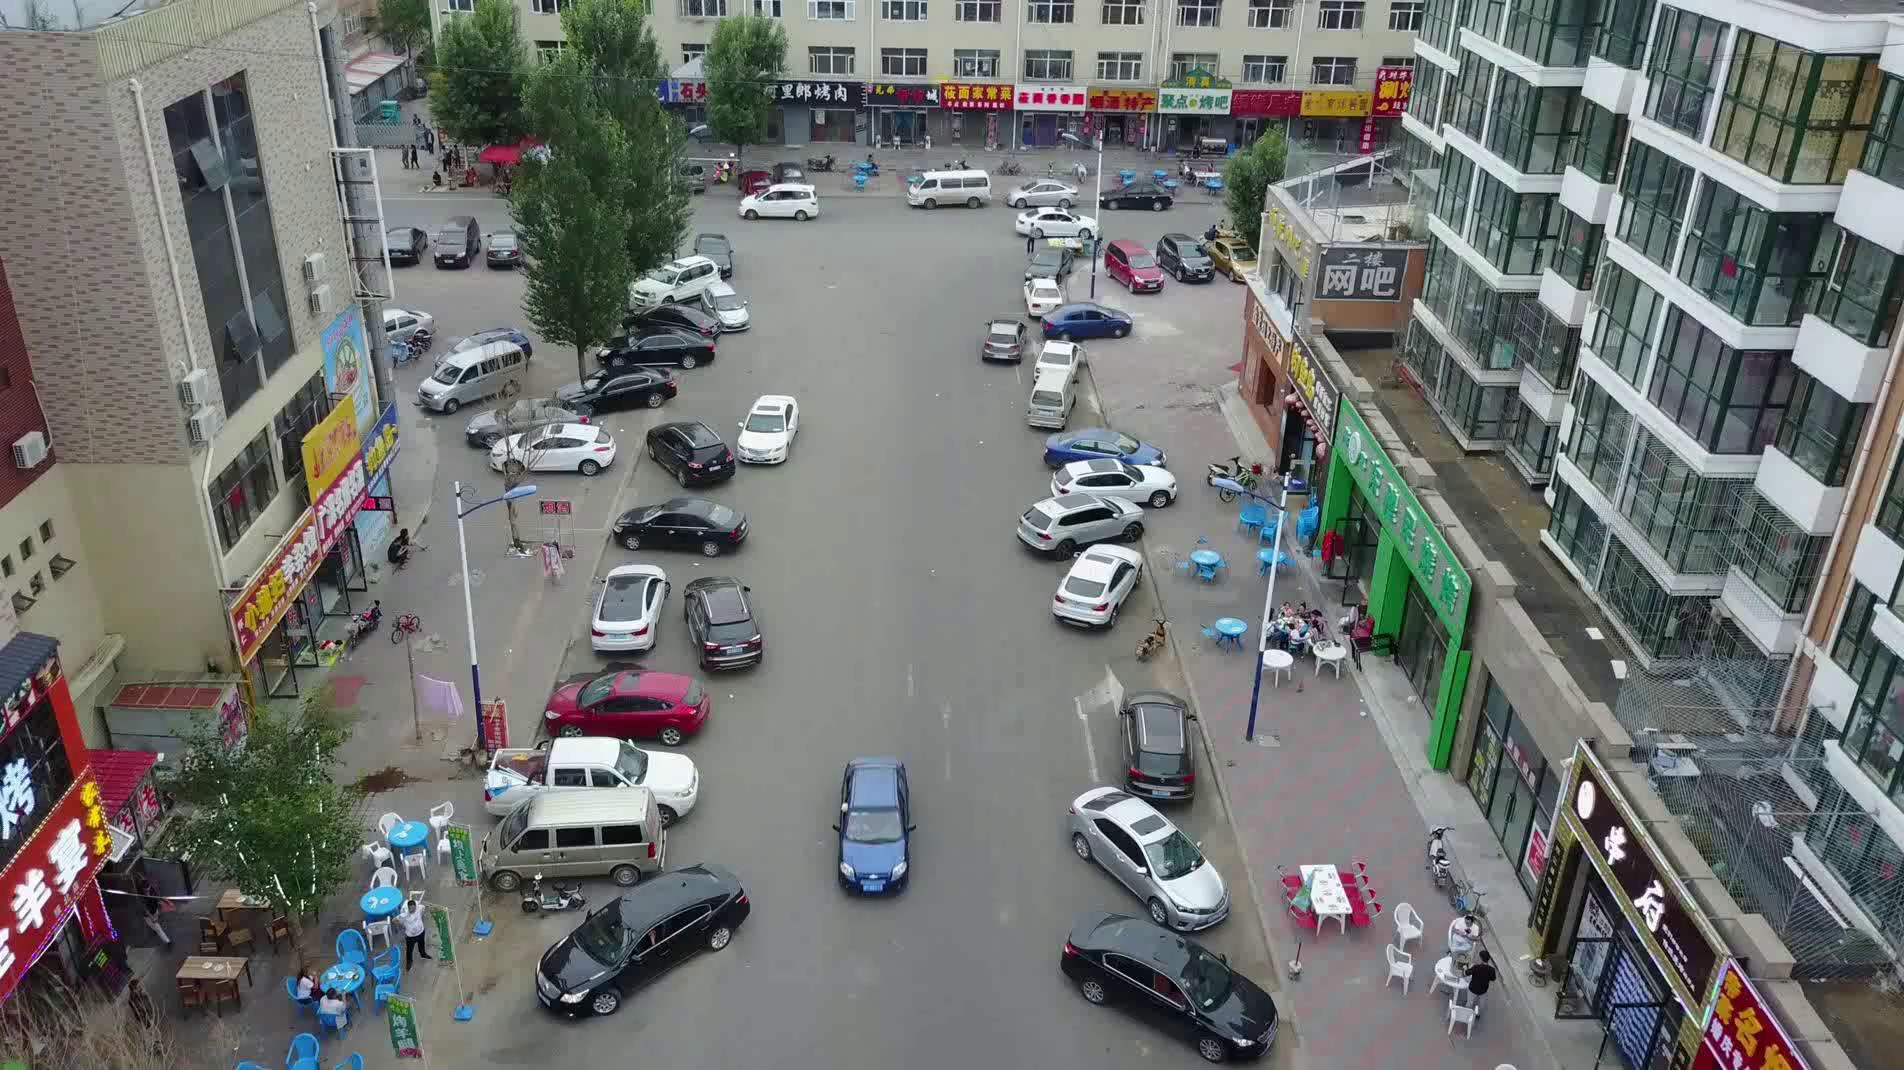

In [69]:
import cv2

VIDEO_PATH = "/content/VisDrone_0001.mp4"

cap = cv2.VideoCapture(VIDEO_PATH)

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print("FPS:", fps)
print("Total frames:", total_frames)
print("Resolution:", width, "x", height)
print("Duration:", total_frames / fps, "seconds")

ret, frame = cap.read()

if ret:
    from google.colab.patches import cv2_imshow
    cv2_imshow(frame)

cap.release()

In [72]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 6.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [73]:
from ultralytics import YOLO

WEIGHTS_PATH = "/content/uav_target_detector.pt"

model = YOLO(WEIGHTS_PATH)

print("Model classes:", model.names)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Model classes: {0: 'tracked_target'}


In [74]:
import cv2
import numpy as np
from ultralytics import YOLO
from tqdm import tqdm

VIDEO_PATH = "/content/VisDrone_0001.mp4"
OUTPUT_PATH = "/content/yolo_bytetrack.mp4"

cap = cv2.VideoCapture(VIDEO_PATH)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

fourcc = cv2.VideoWriter_fourcc(*"mp4v")

out = cv2.VideoWriter(
    OUTPUT_PATH,
    fourcc,
    fps,
    (width, height)
)

track_ids_per_frame = []
detection_counts = []

for frame_idx in tqdm(range(total_frames)):

    ret, frame = cap.read()

    if not ret:
        break

    results = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        conf=0.25,
        iou=0.5,
        verbose=False
    )

    result = results[0]

    annotated_frame = result.plot()

    if result.boxes is not None and result.boxes.id is not None:

        track_ids = result.boxes.id.cpu().numpy().astype(int)
        detection_counts.append(len(track_ids))
        track_ids_per_frame.append(track_ids.tolist())

    else:
        detection_counts.append(0)
        track_ids_per_frame.append([])

    out.write(annotated_frame)

cap.release()
out.release()

print("Tracking completed")
print("Processed frames:", len(detection_counts))
print("Average detections per frame:", np.mean(detection_counts))
print("Unique track IDs:", len(set(
    tid for frame_ids in track_ids_per_frame
    for tid in frame_ids
)))
print("Output:", OUTPUT_PATH)

  0%|          | 0/196 [00:00<?, ?it/s]

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 596ms
Prepared 1 package in 79ms
Installed 1 package in 3ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 1.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



100%|██████████| 196/196 [00:28<00:00,  6.81it/s]

Tracking completed
Processed frames: 196
Average detections per frame: 0.6428571428571429
Unique track IDs: 13
Output: /content/yolo_bytetrack.mp4


In [76]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.spatial.transform import Rotation

VIDEO_PATH = "/content/VisDrone_0001.mp4"

cap = cv2.VideoCapture(VIDEO_PATH)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

cap.release()

# Approximate camera intrinsics
fx = width * 0.8
fy = width * 0.8
cx = width / 2
cy = height / 2

K = np.array([
    [fx, 0, cx],
    [0, fy, cy],
    [0, 0, 1]
], dtype=np.float64)

print("Camera matrix:\n", K)

orb = cv2.ORB_create(
    nfeatures=3000,
    scaleFactor=1.2,
    nlevels=8
)

bf = cv2.BFMatcher(cv2.NORM_HAMMING)

Camera matrix:
 [[     1523.2           0         952]
 [          0      1523.2         535]
 [          0           0           1]]


In [77]:
cap = cv2.VideoCapture(VIDEO_PATH)

frames = []

while True:
    ret, frame = cap.read()

    if not ret:
        break

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    frames.append(gray)

cap.release()

print("Total frames loaded:", len(frames))
print("Frame shape:", frames[0].shape)

Total frames loaded: 196
Frame shape: (1070, 1904)


In [78]:
trajectory_mono = [np.zeros(3)]

pose_history_mono = [np.eye(4)]

orientation_history = [[0.0, 0.0, 0.0]]

motion_inliers = []
motion_match_counts = []
motion_failures = []

T_world_camera = np.eye(4)

for i in tqdm(range(1, len(frames))):

    img1 = frames[i-1]
    img2 = frames[i]

    kp1, des1 = orb.detectAndCompute(img1, None)
    kp2, des2 = orb.detectAndCompute(img2, None)

    if des1 is None or des2 is None:
        motion_failures.append(i)
        pose_history_mono.append(T_world_camera.copy())
        trajectory_mono.append(T_world_camera[:3, 3].copy())
        orientation_history.append(
            orientation_history[-1].copy()
        )
        continue

    matches = bf.knnMatch(des1, des2, k=2)

    good_matches = [
        m for pair in matches if len(pair) == 2
        for m, n in [pair]
        if m.distance < 0.75 * n.distance
    ]

    motion_match_counts.append(len(good_matches))

    if len(good_matches) < 8:
        motion_failures.append(i)
        pose_history_mono.append(T_world_camera.copy())
        trajectory_mono.append(T_world_camera[:3, 3].copy())
        orientation_history.append(
            orientation_history[-1].copy()
        )
        continue

    pts1 = np.float32([
        kp1[m.queryIdx].pt for m in good_matches
    ])

    pts2 = np.float32([
        kp2[m.trainIdx].pt for m in good_matches
    ])

    E, mask = cv2.findEssentialMat(
        pts1,
        pts2,
        K,
        method=cv2.RANSAC,
        prob=0.999,
        threshold=1.0
    )

    if E is None:
        motion_failures.append(i)
        pose_history_mono.append(T_world_camera.copy())
        trajectory_mono.append(T_world_camera[:3, 3].copy())
        orientation_history.append(
            orientation_history[-1].copy()
        )
        continue

    inlier_mask = mask.ravel().astype(bool)

    points1 = pts1[inlier_mask]
    points2 = pts2[inlier_mask]

    if len(points1) < 8:
        motion_failures.append(i)
        pose_history_mono.append(T_world_camera.copy())
        trajectory_mono.append(T_world_camera[:3, 3].copy())
        orientation_history.append(
            orientation_history[-1].copy()
        )
        continue

    pose_inliers, R, t, pose_mask = cv2.recoverPose(
        E,
        points1,
        points2,
        K
    )

    if pose_inliers < 8:
        motion_failures.append(i)
        pose_history_mono.append(T_world_camera.copy())
        trajectory_mono.append(T_world_camera[:3, 3].copy())
        orientation_history.append(
            orientation_history[-1].copy()
        )
        continue

    # Relative transform: previous camera -> current camera
    T_current_previous = np.eye(4)
    T_current_previous[:3, :3] = R
    T_current_previous[:3, 3] = t.flatten()

    # Invert to obtain current camera pose in world coordinates
    T_world_camera = (
        T_world_camera @ np.linalg.inv(T_current_previous)
    )

    # Camera orientation relative to initial world frame
    euler = Rotation.from_matrix(
        T_world_camera[:3, :3]
    ).as_euler("xyz", degrees=True)

    pose_history_mono.append(T_world_camera.copy())
    trajectory_mono.append(T_world_camera[:3, 3].copy())
    orientation_history.append(euler.tolist())

    motion_inliers.append(pose_inliers)


trajectory_mono = np.asarray(trajectory_mono)
pose_history_mono = np.asarray(pose_history_mono)
orientation_history = np.asarray(orientation_history)

print("\nVO completed")
print("Trajectory shape:", trajectory_mono.shape)
print("Successful frames:", len(frames) - 1 - len(motion_failures))
print("Failed frames:", len(motion_failures))
print("Average Essential Matrix pose inliers:",
      np.mean(motion_inliers))

100%|██████████| 195/195 [00:49<00:00,  3.95it/s]



VO completed
Trajectory shape: (196, 3)
Successful frames: 49
Failed frames: 146
Average Essential Matrix pose inliers: 23.959183673469386


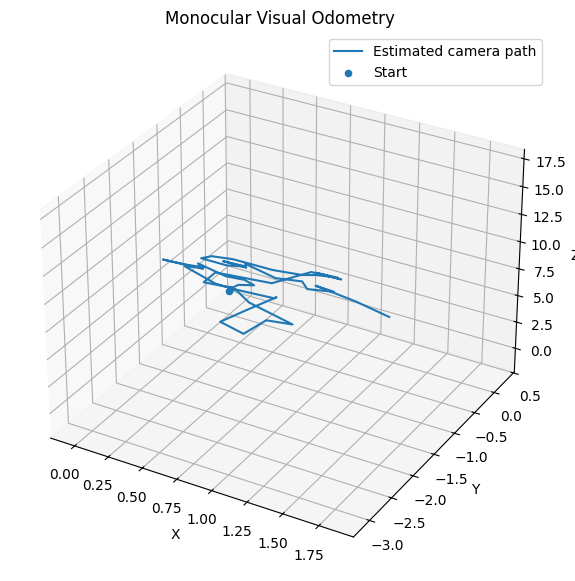

In [79]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot(
    trajectory_mono[:, 0],
    trajectory_mono[:, 1],
    trajectory_mono[:, 2],
    label="Estimated camera path"
)

ax.scatter(0, 0, 0, marker="o", label="Start")

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title("Monocular Visual Odometry")
ax.legend()
plt.show()

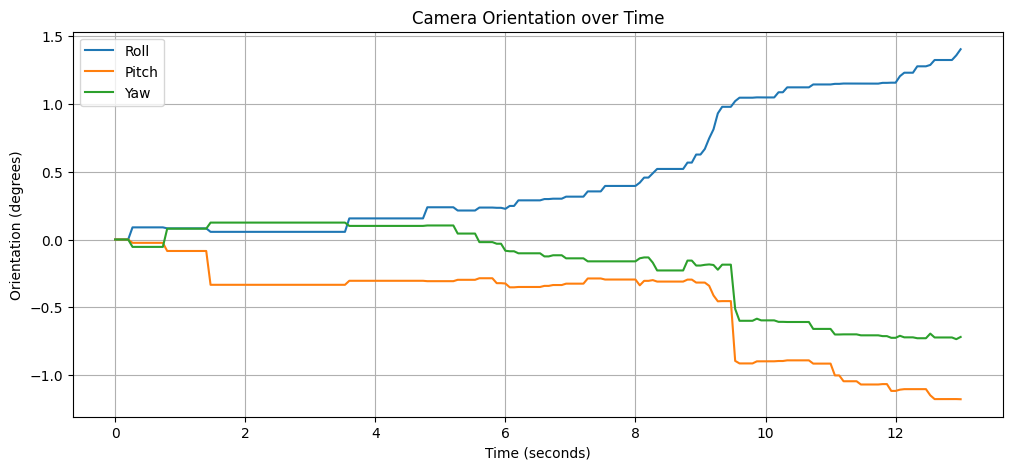

In [80]:
time_axis = np.arange(len(orientation_history)) / fps

plt.figure(figsize=(12, 5))

plt.plot(time_axis, orientation_history[:, 0], label="Roll")
plt.plot(time_axis, orientation_history[:, 1], label="Pitch")
plt.plot(time_axis, orientation_history[:, 2], label="Yaw")

plt.xlabel("Time (seconds)")
plt.ylabel("Orientation (degrees)")
plt.title("Camera Orientation over Time")
plt.legend()
plt.grid(True)
plt.show()

In [81]:
print("Video frames:", len(frames))
print("YOLO tracking frames:", len(track_ids_per_frame))
print("VO pose frames:", len(pose_history_mono))
print("Orientation frames:", len(orientation_history))

assert len(track_ids_per_frame) == len(frames)
assert len(pose_history_mono) == len(frames)
assert len(orientation_history) == len(frames)

Video frames: 196
YOLO tracking frames: 196
VO pose frames: 196
Orientation frames: 196


In [82]:
import cv2
import numpy as np
from collections import defaultdict
from tqdm import tqdm

INPUT_PATH = VIDEO_PATH
OUTPUT_PATH = "/content/uav_perception_fusion.mp4"

cap = cv2.VideoCapture(INPUT_PATH)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

out = cv2.VideoWriter(
    OUTPUT_PATH,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height)
)

trajectory_points = []

for i in tqdm(range(len(frames))):

    ret, frame = cap.read()

    if not ret:
        break

    # Camera orientation
    roll, pitch, yaw = orientation_history[i]

    # Camera translation (monocular scale)
    x, y, z = trajectory_mono[i]

    # YOLO + ByteTrack results
    results = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        conf=0.25,
        iou=0.5,
        verbose=False
    )

    result = results[0]

    if result.boxes is not None and result.boxes.id is not None:

        boxes = result.boxes.xyxy.cpu().numpy()
        ids = result.boxes.id.cpu().numpy().astype(int)

        for box, track_id in zip(boxes, ids):

            x1, y1, x2, y2 = map(int, box)

            cv2.rectangle(
                frame,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

            cv2.putText(
                frame,
                f"Target ID: {track_id}",
                (x1, max(25, y1 - 10)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (0, 255, 0),
                2
            )

    # Camera information panel
    cv2.rectangle(frame, (15, 15), (500, 175), (0, 0, 0), -1)

    cv2.putText(frame, "UAV PERCEPTION SYSTEM",
                (30, 42), cv2.FONT_HERSHEY_SIMPLEX,
                0.8, (255, 255, 255), 2)

    cv2.putText(frame, f"Roll: {roll:.2f} deg",
                (30, 75), cv2.FONT_HERSHEY_SIMPLEX,
                0.65, (0, 255, 255), 2)

    cv2.putText(frame, f"Pitch: {pitch:.2f} deg",
                (30, 105), cv2.FONT_HERSHEY_SIMPLEX,
                0.65, (0, 255, 255), 2)

    cv2.putText(frame, f"Yaw: {yaw:.2f} deg",
                (30, 135), cv2.FONT_HERSHEY_SIMPLEX,
                0.65, (0, 255, 255), 2)

    cv2.putText(frame, f"VO: ({x:.2f}, {y:.2f}, {z:.2f})",
                (30, 165), cv2.FONT_HERSHEY_SIMPLEX,
                0.55, (255, 255, 255), 2)

    trajectory_points.append((x, y, z))

    out.write(frame)

cap.release()
out.release()

print("Integrated video generated:", OUTPUT_PATH)

100%|██████████| 196/196 [00:15<00:00, 13.04it/s]

Integrated video generated: /content/uav_perception_fusion.mp4


In [84]:
import pandas as pd

records = []

for i in range(len(frames)):

    roll, pitch, yaw = orientation_history[i]
    x, y, z = trajectory_mono[i]

    records.append({
        "frame": i,
        "timestamp": i / fps,
        "camera_x": x,
        "camera_y": y,
        "camera_z": z,
        "roll_deg": roll,
        "pitch_deg": pitch,
        "yaw_deg": yaw,
        "track_ids": track_ids_per_frame[i]
    })

perception_df = pd.DataFrame(records)

perception_df.to_csv(
    "/content/uav_perception_data.csv",
    index=False
)

print(perception_df.head())

   frame  timestamp  camera_x  camera_y  camera_z  roll_deg  pitch_deg  \
0      0   0.000000  0.000000  0.000000  0.000000   0.00000   0.000000   
1      1   0.066667  0.000000  0.000000  0.000000   0.00000   0.000000   
2      2   0.133333  0.000000  0.000000  0.000000   0.00000   0.000000   
3      3   0.200000  0.000000  0.000000  0.000000   0.00000   0.000000   
4      4   0.266667 -0.042056  0.277878 -0.959695   0.08964  -0.024497   

    yaw_deg track_ids  
0  0.000000    [1, 2]  
1  0.000000       [1]  
2  0.000000    [1, 2]  
3  0.000000       [2]  
4 -0.054423       [2]  
